## Automating Regional Briefings
Author: Smitha Mahesh, Eric Englin, Sophie Son

Purpose: To complete the analyses and visualizations required for the region-level briefings. 

In [4]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
import seaborn as sns
import docx

In [5]:
myworkingdirectory = r"C:\Users\Sophie.Kaye\Desktop\NPS Crash Data"
os.chdir(myworkingdirectory)

In [7]:
analysis_2024 = pd.read_csv("./analysis_database_2024.csv")

<ipython-input-7-60bb7cbbd6e1>:1: DtypeWarning: Columns (68) have mixed types. Specify dtype option on import or set low_memory=False.
  analysis_2024 = pd.read_csv("./analysis_database_2024.csv")


In [8]:
analysis_2024.shape

(218593, 71)

In [6]:
park_info = pd.read_csv(".//Data//Reference Data/Park_Info_Table.csv")
park_info = park_info.rename(columns={'UNIT_CODE':'Park','REGION':'RGN'})

In [9]:
analysis_2024.columns

Index(['INCID_NO', '5_mph', '10_mph', '15_mph', '20_mph', '25_mph', '30_mph',
       '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph', '65_mph',
       '70_mph', '75_mph', 'no_posted_speed', 'Crosswalk',
       'Outside a Crosswalk', 'NUM_VEH', 'Num_Motorcycle', 'Pax', 'SUV', 'Van',
       'Bus', 'Medium Truck', 'Heavy Truck', 'Equipment', 'Nonroad HighSpeed',
       'Nonroad LowSpeed', 'Unknown', 'Motorcycle_Ind', 'No Injury',
       'Possible Injury', 'Non-incapacitating Injury', 'Incapacitating Injury',
       'Fatality', 'Num_Motorist', 'Num_Non_Motorist', 'Num_Pedestrian',
       'Num_Ped_Deaths', 'Pedestrian', 'VRU', 'Crash_Severity',
       'CrashSeverity_Fatal', 'CrashSeverity_Incap', 'CrashSeverity_NonIncap',
       'CrashSeverity_Possible', 'CrashSeverity_NoInj', 'First_Harmful_Event',
       'First_Harmful_Event_Type', 'Involving Animal', 'Daylight', 'Dawn',
       'Dusk', 'Dark_Lit', 'Dark_NotLit', 'Dark_UnknownLit',
       'UnknownBlankNullLit', 'Poor Lighting', 

## Available Data Fields

In [12]:
def pull_source_table_data(df, region, field, filter_value):
    df = df.loc[df['RGN']==region]
    df = df.loc[df[field]==filter_value]
    parks, crashes = df.groupby("Park").agg({
        'INCID_NO':'count',
    }).reset_index().agg({
        "Park":"count",
        'INCID_NO':sum,
    })
    
    parks = str(parks) + " Park Units"
    crashes = "{:,}".format(crashes) + " Crash Reports"
    
    return parks, crashes

def make_source_table(region):
    CDS_parks, CDS_crash_reports = pull_source_table_data(analysis_2024, region, 'database', 'CDS')
    IMARS_parks, IMARS_crash_reports = pull_source_table_data(analysis_2024, region, 'database', 'IMARS')
    source_list = []
    parks_list = [CDS_parks, IMARS_parks]
    crash_reports_list = [CDS_crash_reports, IMARS_crash_reports]

    final_df = pd.DataFrame({
        "Source":["Crash Data System (CDS)", 
                  "Incident Management Analysis and Reporting System (IMARS)"],
        "Locations": parks_list,
        'Years': ["1989-2013", "2012-present"],
        "Quantity of Data": crash_reports_list
    })
    
    return final_df

In [22]:
make_source_table("AKR")

,Source,Locations,Years,Quantity of Data
0,Crash Data System (CDS),5 Park Units,1989-2013,236 Crash Reports
1,Incident Management Analysis and Reporting Sys...,7 Park Units,2012-present,119 Crash Reports


## Regional Trends

### Crash Outcomes by Park

In [23]:
def create_park_table(region):
    region = analysis_2024.loc[analysis_2024['RGN']==region]
    region_slim = region[['Park', 'Fatality', 'Incapacitating Injury']]
    region_parks = region_slim.groupby(by=['Park'], as_index=False).sum()
    region_parks['Number of Fatalities'] = region_parks['Fatality'].astype(int)
    region_parks['Number of Serious Injuries'] = region_parks['Incapacitating Injury'].astype(int)
    region_parks = region_parks.drop(columns={'Fatality','Fatality', 'Incapacitating Injury'})

    return region_parks

In [24]:
create_park_table("NCR")

,Park,Number of Fatalities,Number of Serious Injuries
0,ANAC,0,1
1,ANTI,0,3
2,ARHO,0,1
3,BARC,0,0
4,BAWA,265,1104
5,CATO,0,4
6,CAWO,0,0
7,CHND,1,0
8,CHOH,5,7
9,CLBA,2,8


### All Crashes

### All Crashes by Speed Limit

In [73]:
def create_posted_speed_fig(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2024.loc[analysis_2024['RGN']==region]
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    fatalities = []
    serious_injuries = []
    crashes = []
    
    for i in speed_columns:
        num_fatalities = df.loc[df[i]==1]['Fatality'].sum()
        fatalities.append(num_fatalities)
        num_serious_injuries = df.loc[df[i]==1]['Incapacitating Injury'].sum()
        serious_injuries.append(num_serious_injuries)    
        num_crashes = df.loc[df[i]==1].shape[0]
        crashes.append(num_crashes)
    
    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('All Crashes by Speed Limit: ' + region, fontsize=30)

    # subplot data
    ax[0].bar(speed_list, fatalities, width = 5, hatch = "\\", edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, serious_injuries, width = 5, hatch = "/", edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, crashes, width = 5, hatch = "x", edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

<ipython-input-73-bf66a9cff379>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-73-bf66a9cff379>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-73-bf66a9cff379>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.styl

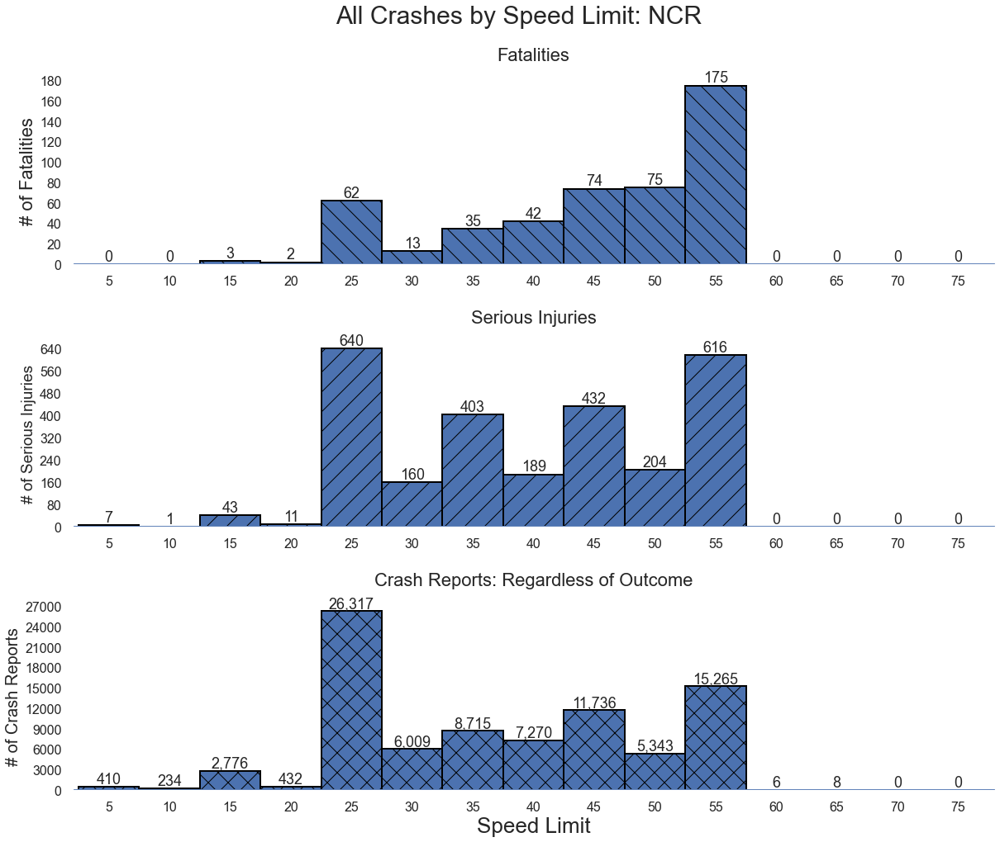

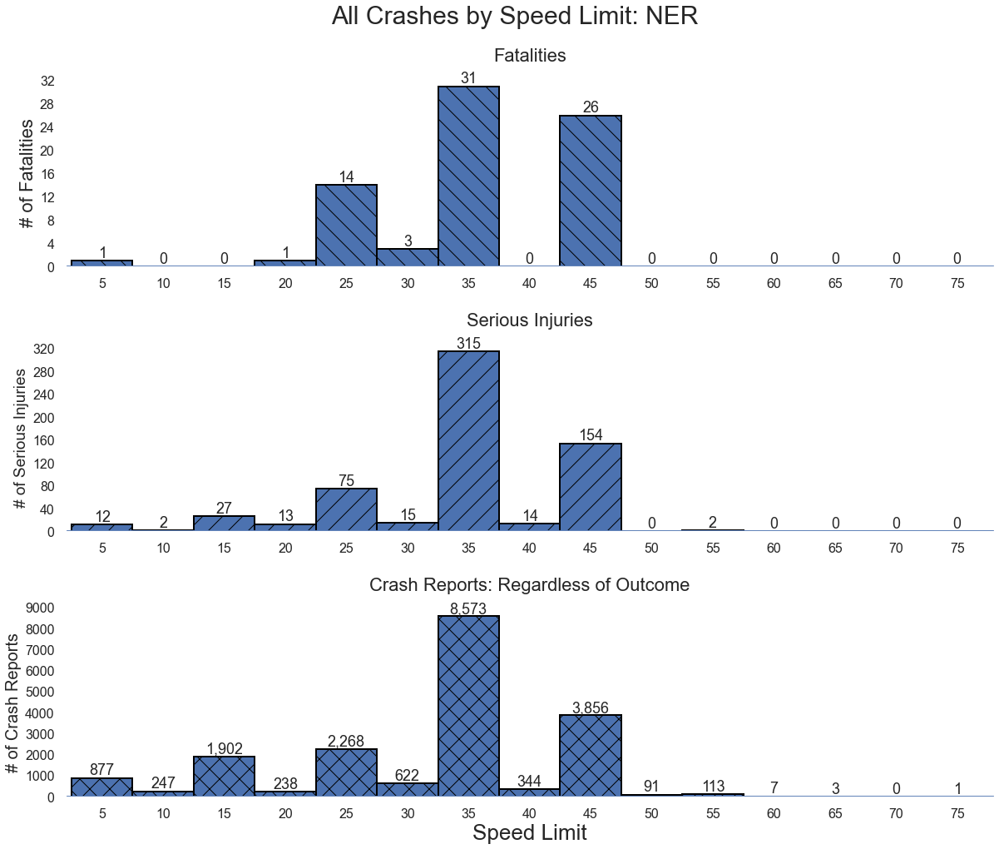

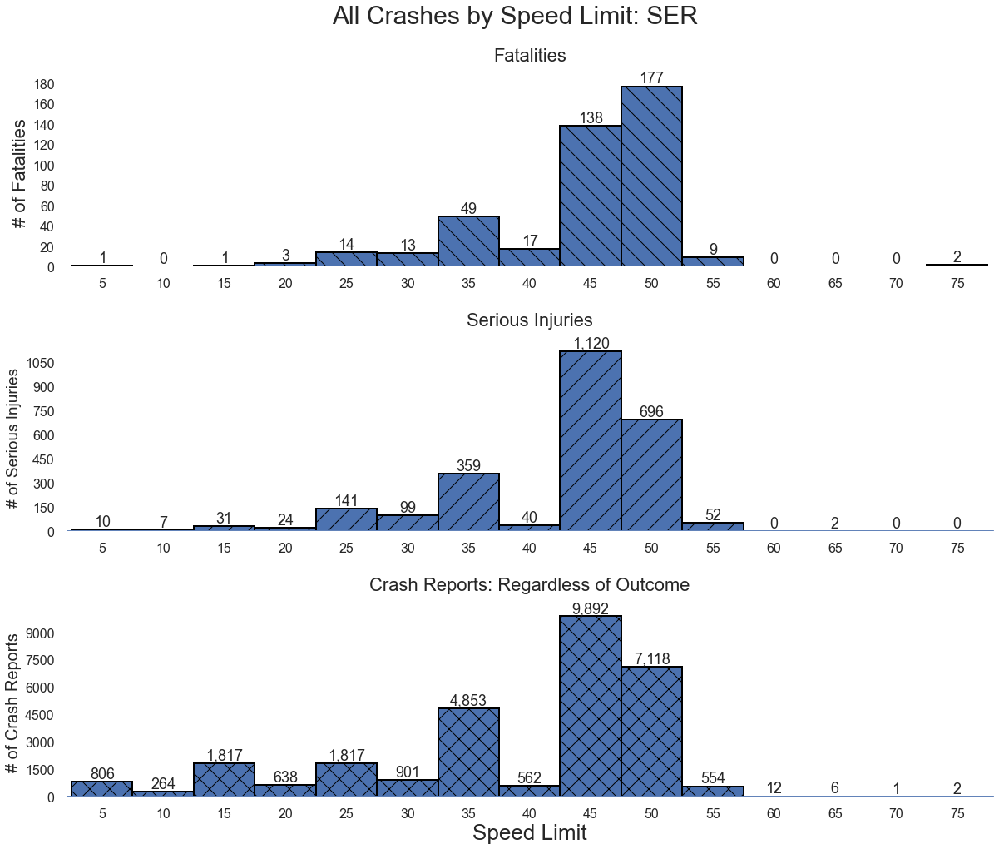

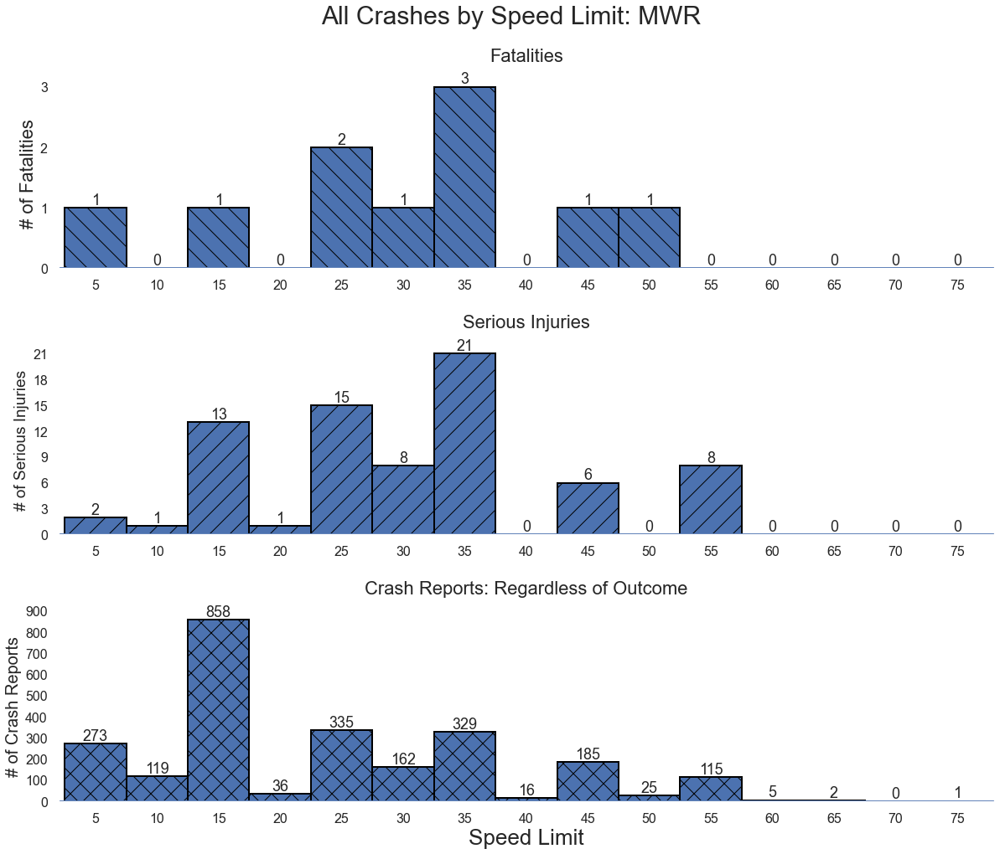

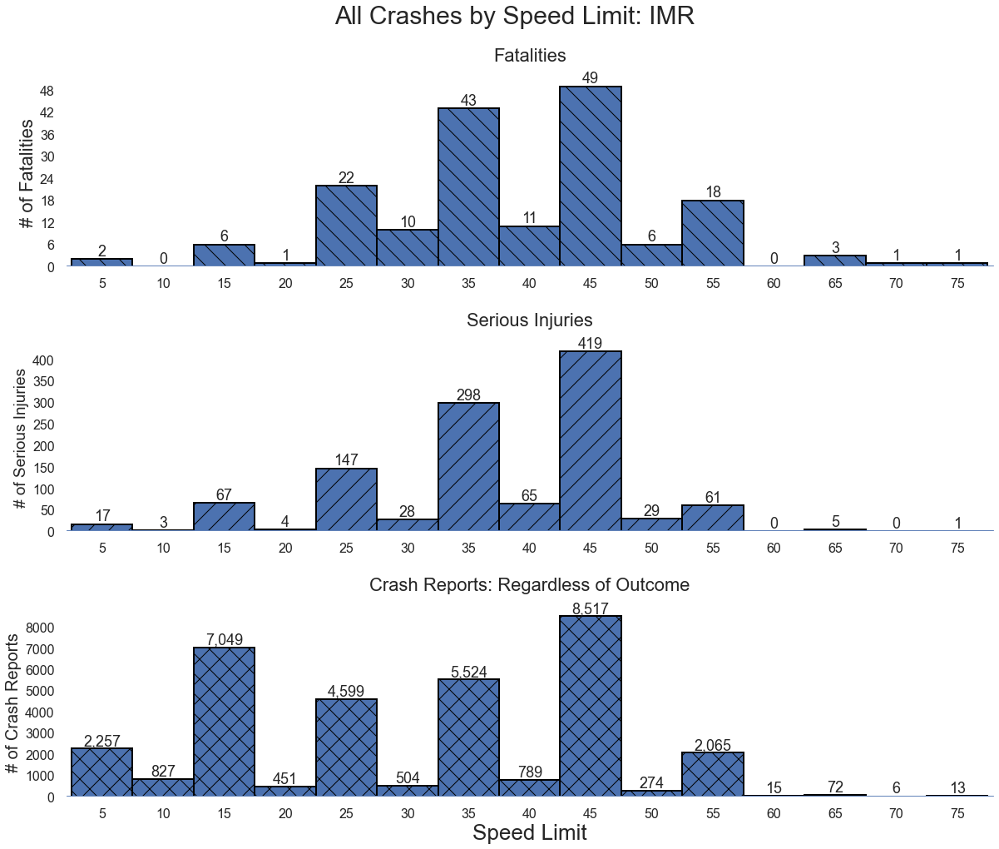

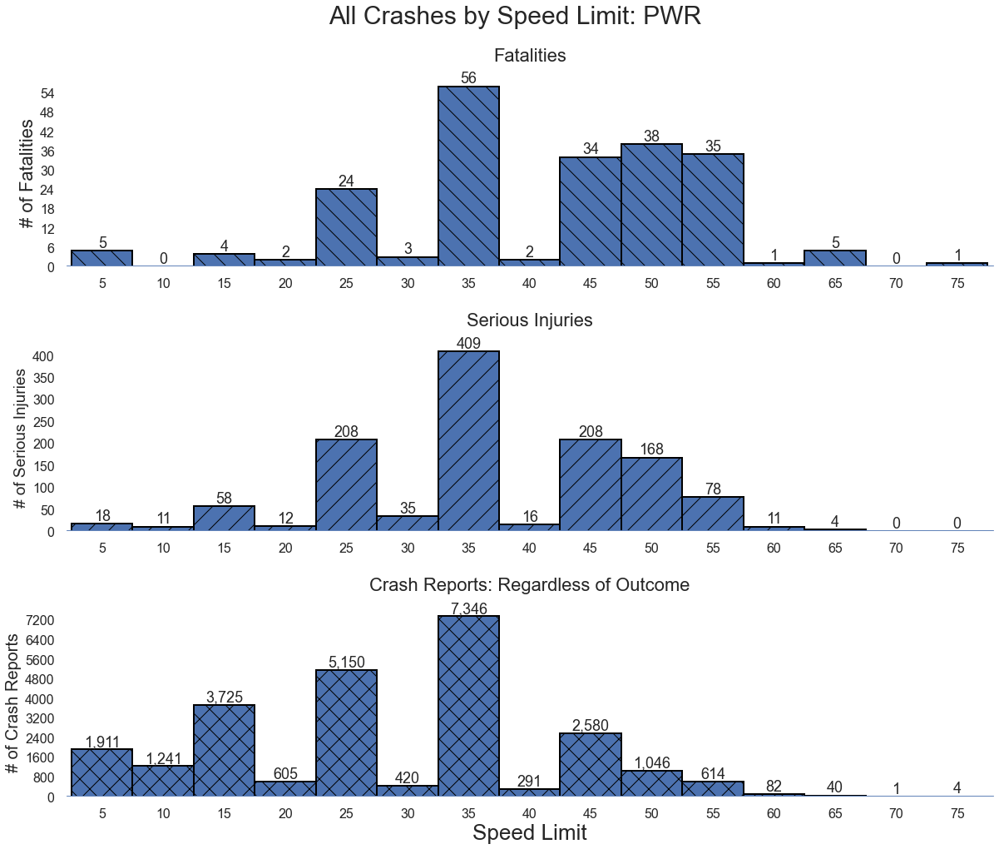

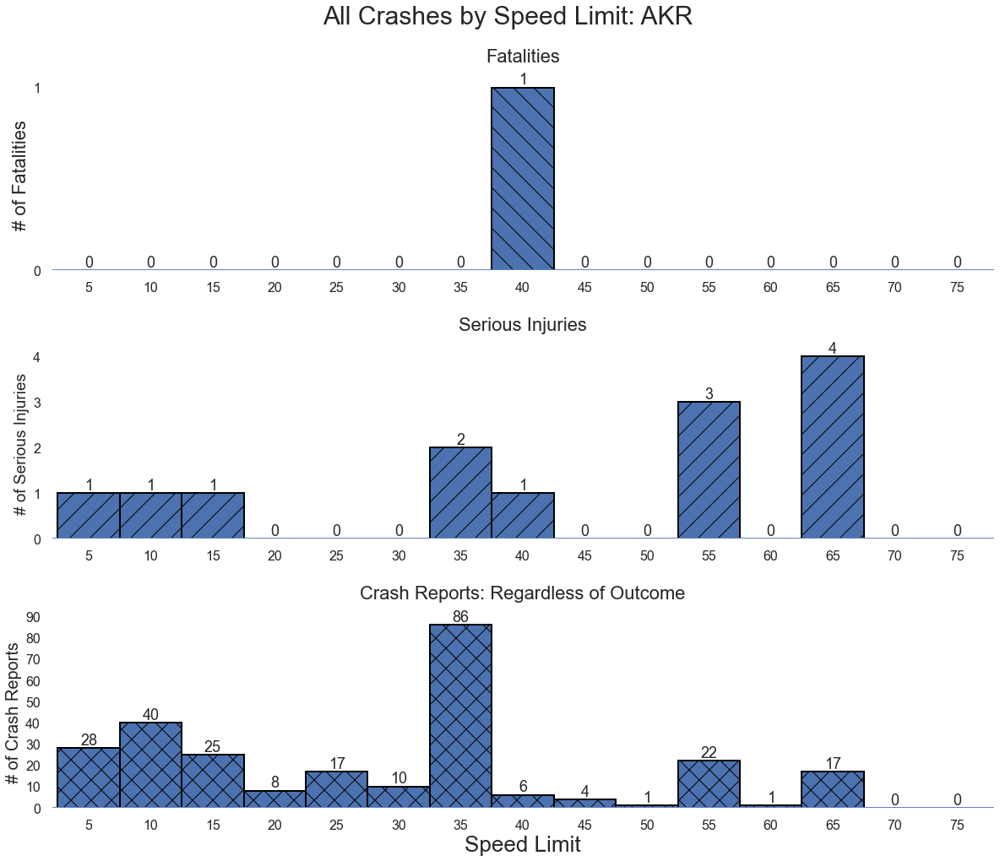

In [82]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    create_posted_speed_fig(region)

### All Crashes Resulting in an Injury or Fatality

In [76]:
def create_inj_or_fatal_fig(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2024.loc[analysis_2024['RGN']==region]
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    inj_or_fatal = df.loc[df['Crash_Severity'].isin(["Fatal","Incap"])]
    vru_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['VRU']==1]
    animal_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['Involving Animal']==1]
    VRU_crashes = []
    wildlife_crashes = []
    all_crashes = []

    for i in speed_columns:
        num_VRU_crashes = vru_inj_or_fatal.loc[vru_inj_or_fatal[i]==1].shape[0]
        VRU_crashes.append(num_VRU_crashes)
        num_wildlife_crashes = animal_inj_or_fatal.loc[animal_inj_or_fatal[i]==1].shape[0]
        wildlife_crashes.append(num_wildlife_crashes)    
        num_all_crashes = inj_or_fatal.loc[inj_or_fatal[i]==1].shape[0]
        all_crashes.append(num_all_crashes)
    
   # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('Crashes Resulting in a Serious Injury or Fatality: ' + region, fontsize=30)

    # subplot data
    ax[0].bar(speed_list, VRU_crashes, width = 5, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, wildlife_crashes, width = 5, hatch = "/", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, all_crashes, width = 5, hatch = "x", edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Crashes Involving VRUs",fontsize= 22, pad = 20)
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Crashes Involving Wildlife",fontsize= 22, pad = 20)
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Involvement",fontsize= 22, pad = 20)
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 22)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

<ipython-input-76-869b918c8bec>:22: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-76-869b918c8bec>:22: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-76-869b918c8bec>:22: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.styl

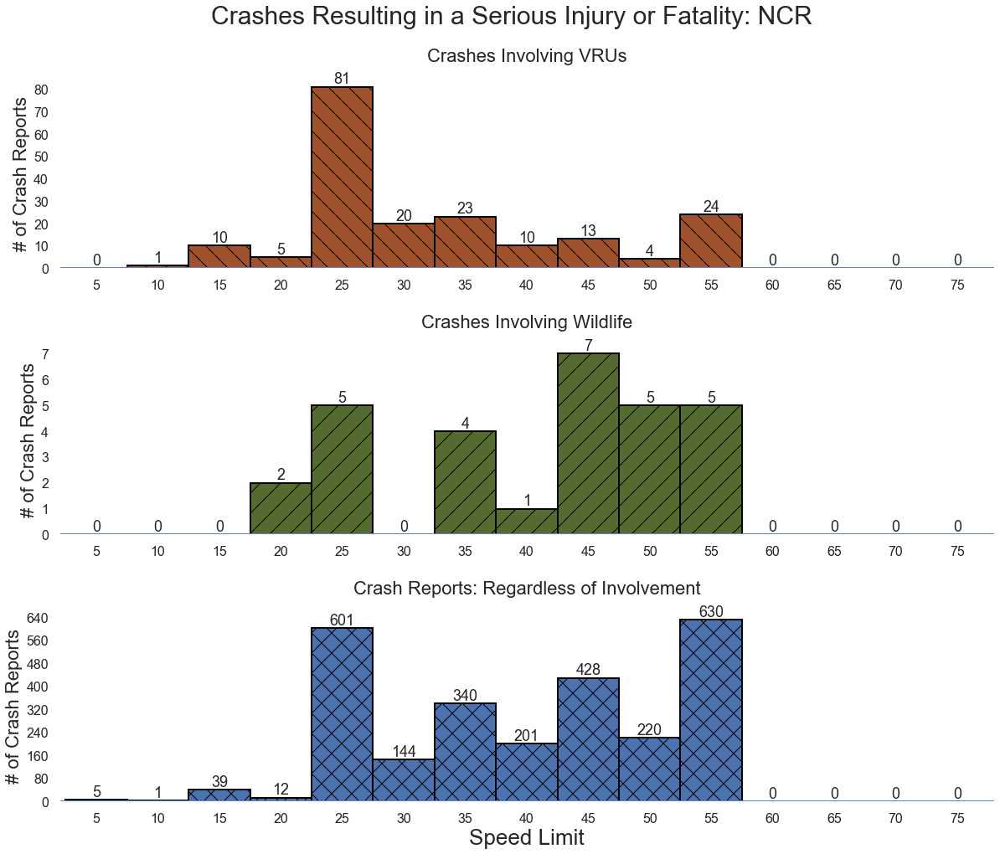

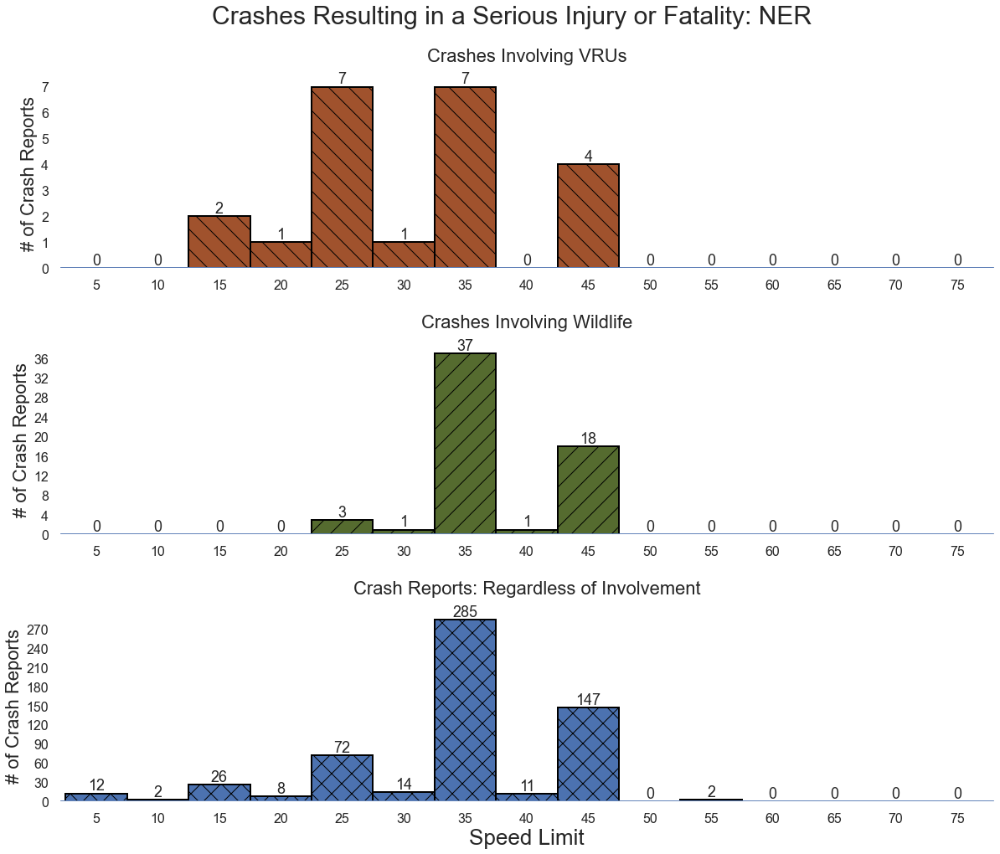

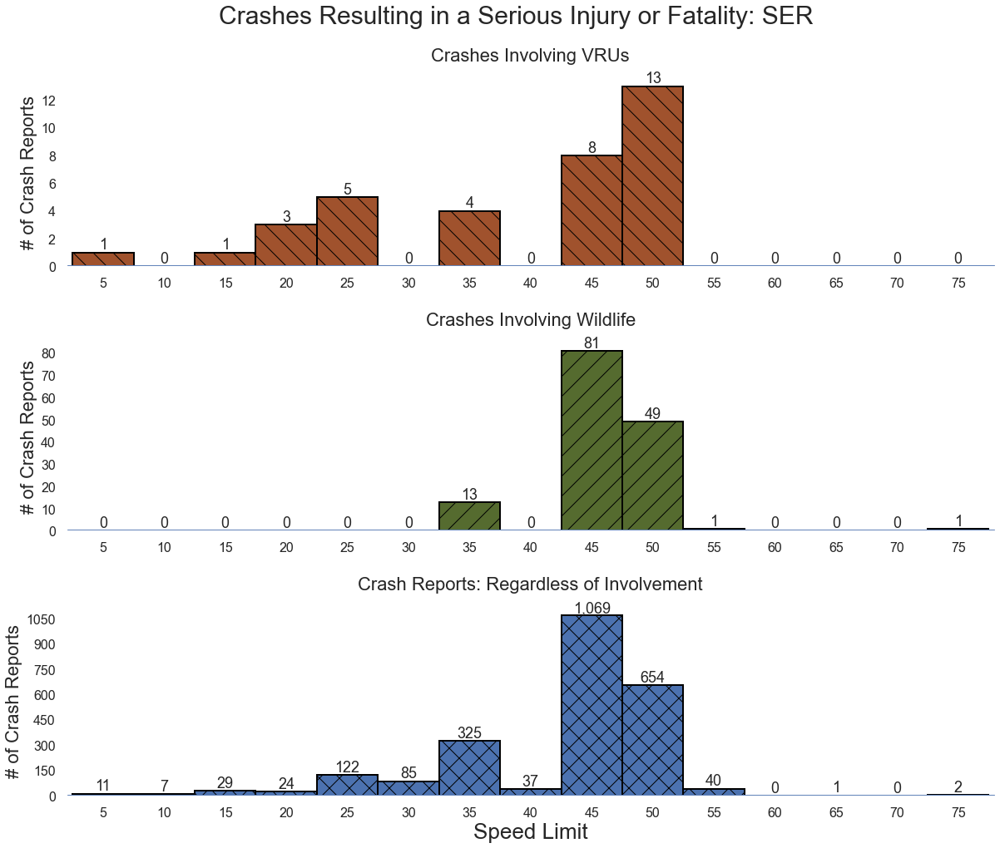

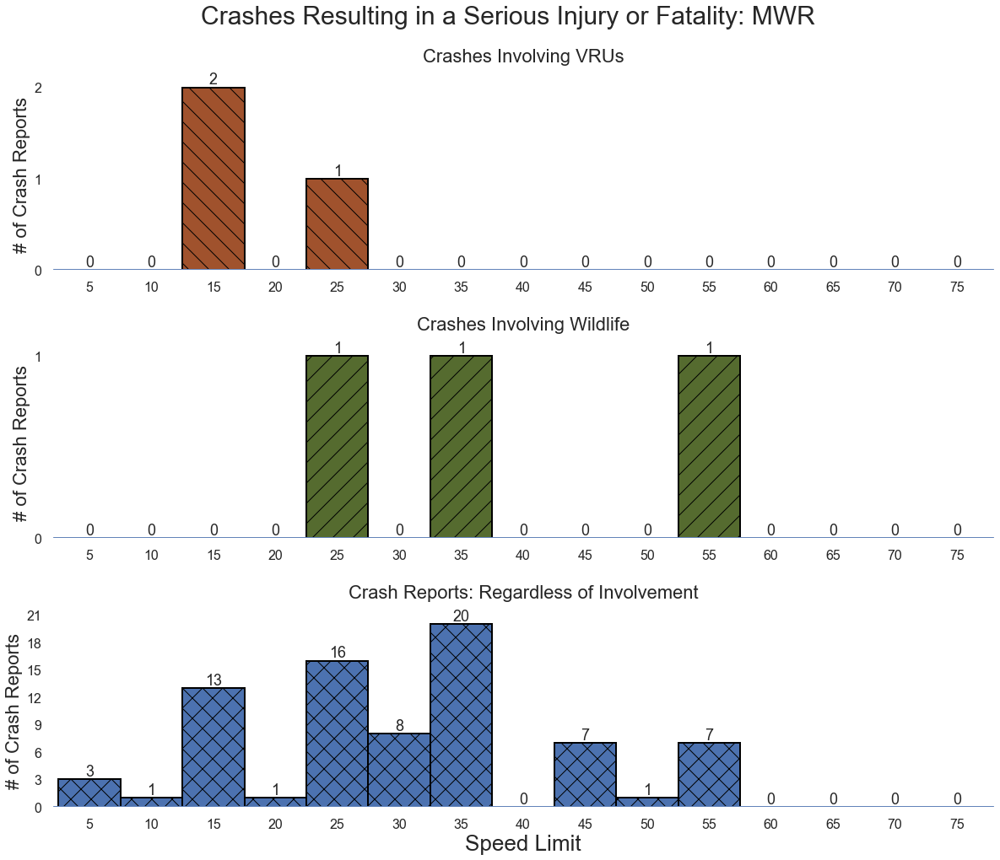

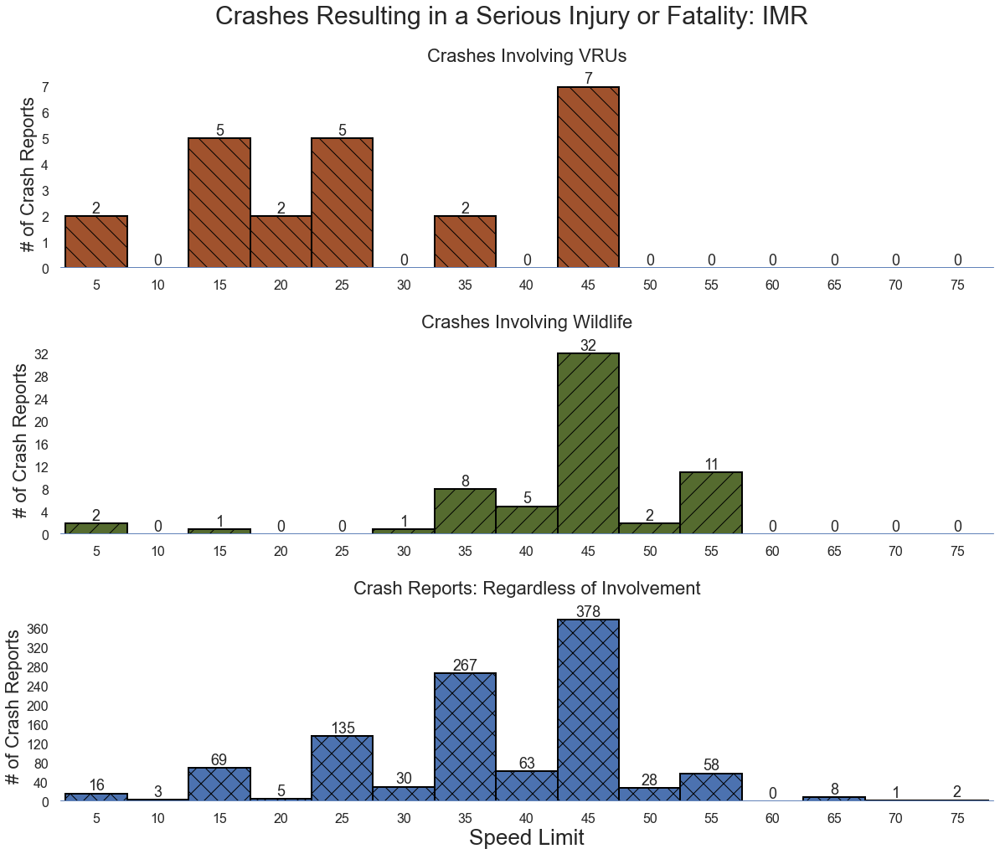

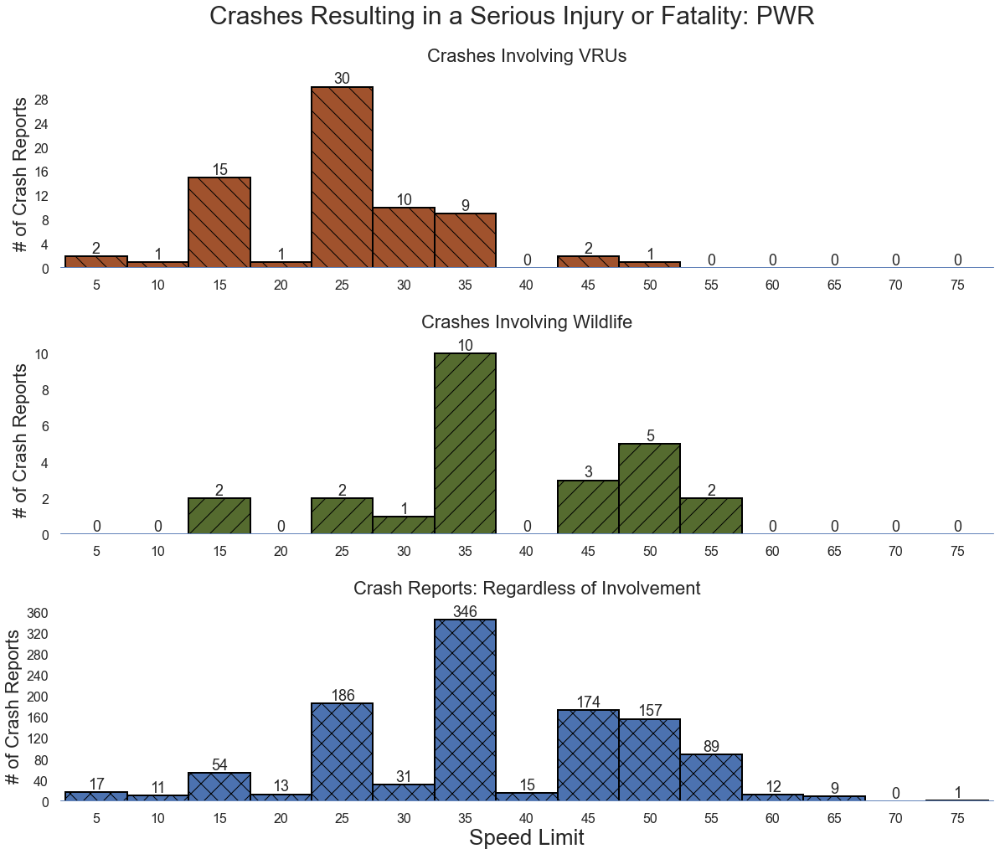

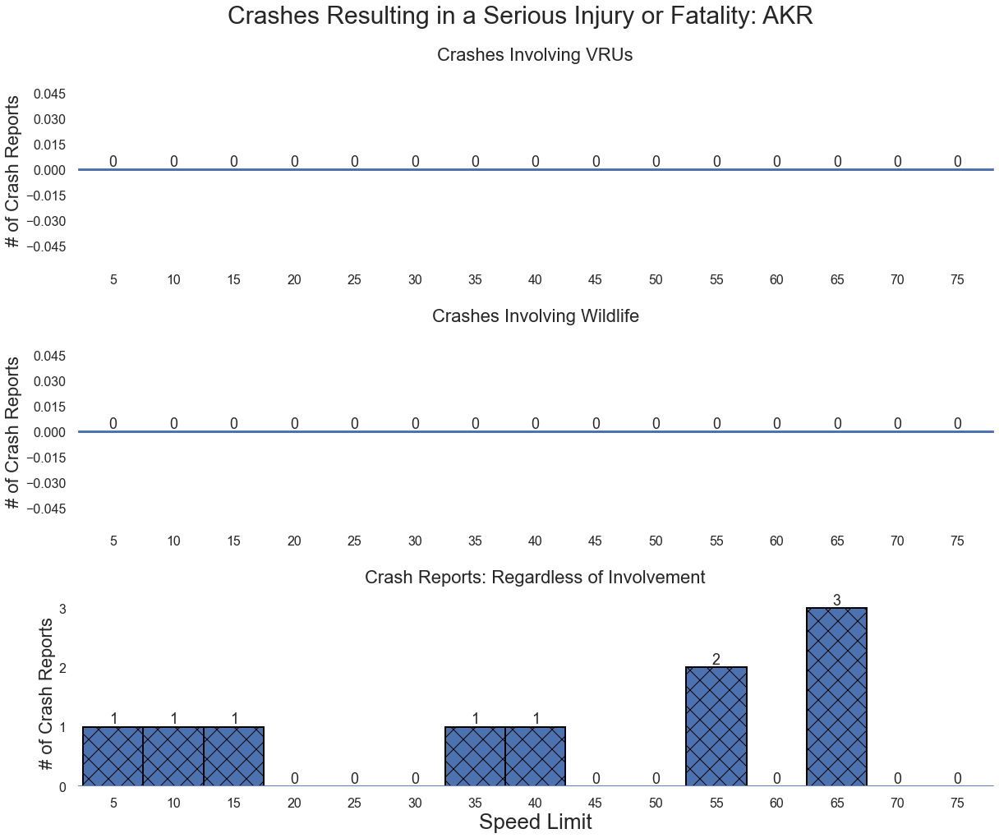

In [81]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    create_inj_or_fatal_fig(region)

### Wildlife crashes

### Crashes Involving Wildlife, Regional and National 

In [65]:
def create_wildlife_crashes_table(region):
    inj_or_fatal = analysis_2024.loc[analysis_2024['Crash_Severity'].isin(["Fatal","Incap"])]
    animal_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['Involving Animal']==1]
    rgn = analysis_2024.loc[analysis_2024['RGN']==region]
    animal = analysis_2024.loc[analysis_2024['Involving Animal']==1]
    animal_region = animal.loc[animal['RGN']==region]
    animal_inj_or_fatal_region = animal_inj_or_fatal.loc[animal_inj_or_fatal['RGN']==region]
    animal_percent_region = round(animal_region.shape[0]/rgn.shape[0]*100,2)
    animal_inj_or_fatal_percent_region = round(animal_inj_or_fatal_region.shape[0]/animal_region.shape[0]*100,2)
    animal_serious_injury_region = int(animal_region['Incapacitating Injury'].sum())
    animal_fatals_region = int(animal_region['Fatality'].sum())
        
    animal_percent = round(animal.shape[0]/analysis_2024.shape[0]*100,2)
    animal_inj_or_fatal_percent = round(animal_inj_or_fatal.shape[0]/animal.shape[0]*100,2)
    animal_serious_injury = int(animal['Incapacitating Injury'].sum())
    animal_fatals = int(animal['Fatality'].sum())
    
    df_final = pd.DataFrame({
    "Fields": ["Percent of Total Crashes", "Percent of Wildlife Crashes that Resulted in a Serious Injury/Fatality", "Number of Serious Injuries", "Number of Fatalities"],
    region: [str(animal_percent_region) + "%", str(animal_inj_or_fatal_percent_region) + "%", animal_serious_injury_region, animal_fatals_region], 
    "National": [str(animal_percent) + "%", str(animal_inj_or_fatal_percent) + "%", animal_serious_injury, animal_fatals]
     })
    
    return df_final

In [66]:
create_wildlife_crashes_table("NCR")

,Fields,NCR,National
0,Percent of Total Crashes,2.7%,10.86%
1,Percent of Wildlife Crashes that Resulted in a...,1.1%,1.41%
2,Number of Serious Injuries,28,355
3,Number of Fatalities,3,32


### Wildlife Crashes by Speed Limit

In [78]:
def create_posted_speed_fig_animals(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2024.loc[analysis_2024['RGN']==region]   
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    animal = df.loc[df['Involving Animal']==1]
    animal_fatalities = []
    animal_serious_injuries = []
    animal_crashes = []

    for i in speed_columns:
        num_animal_fatalities = animal.loc[animal[i]==1]['Fatality'].sum()
        animal_fatalities.append(num_animal_fatalities)
        num_animal_serious_injuries = animal.loc[animal[i]==1]['Incapacitating Injury'].sum()
        animal_serious_injuries.append(num_animal_serious_injuries)    
        num_animal_crashes = animal.loc[animal[i]==1].shape[0]
        animal_crashes.append(num_animal_crashes)
        
    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('Wildlife Crashes by Speed Limit: ' + region, fontsize=30)

    # subplot data
    ax[0].bar(speed_list, animal_fatalities, width = 5, hatch = "\\", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, animal_serious_injuries, width = 5, hatch = "/", color = 'darkolivegreen', edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, animal_crashes, width = 5, hatch = "x", color = 'darkolivegreen', edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

<ipython-input-78-bc16a15e1469>:20: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-78-bc16a15e1469>:20: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-78-bc16a15e1469>:20: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.styl

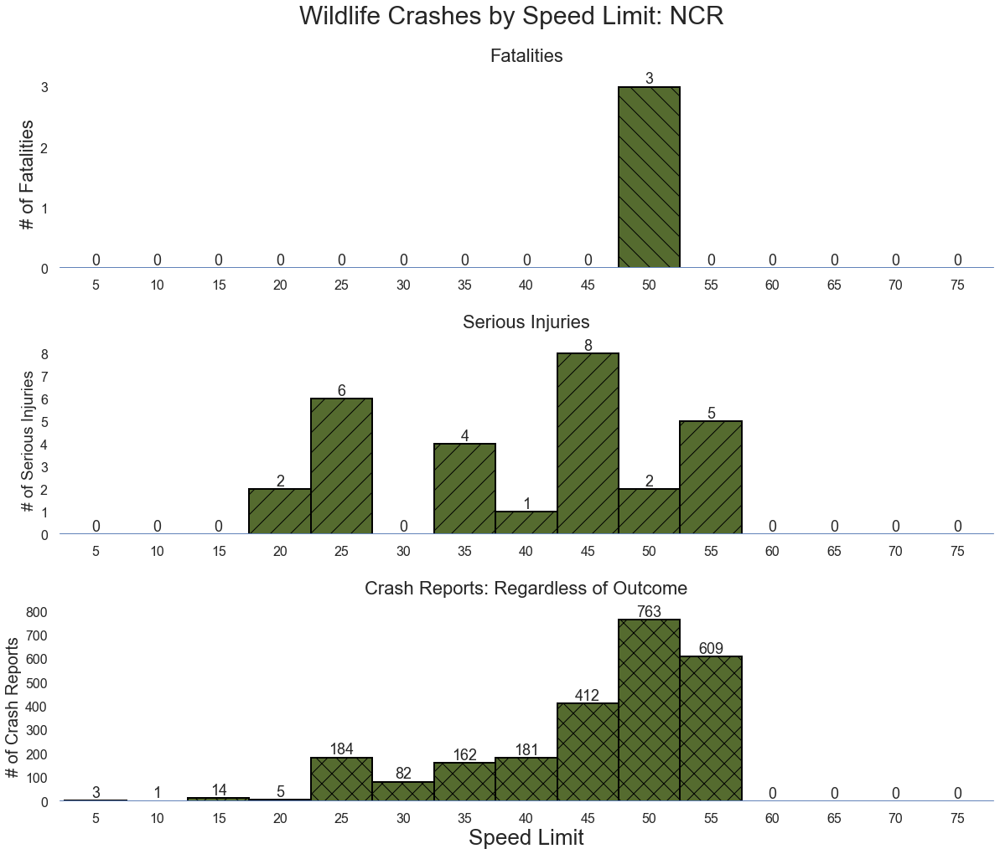

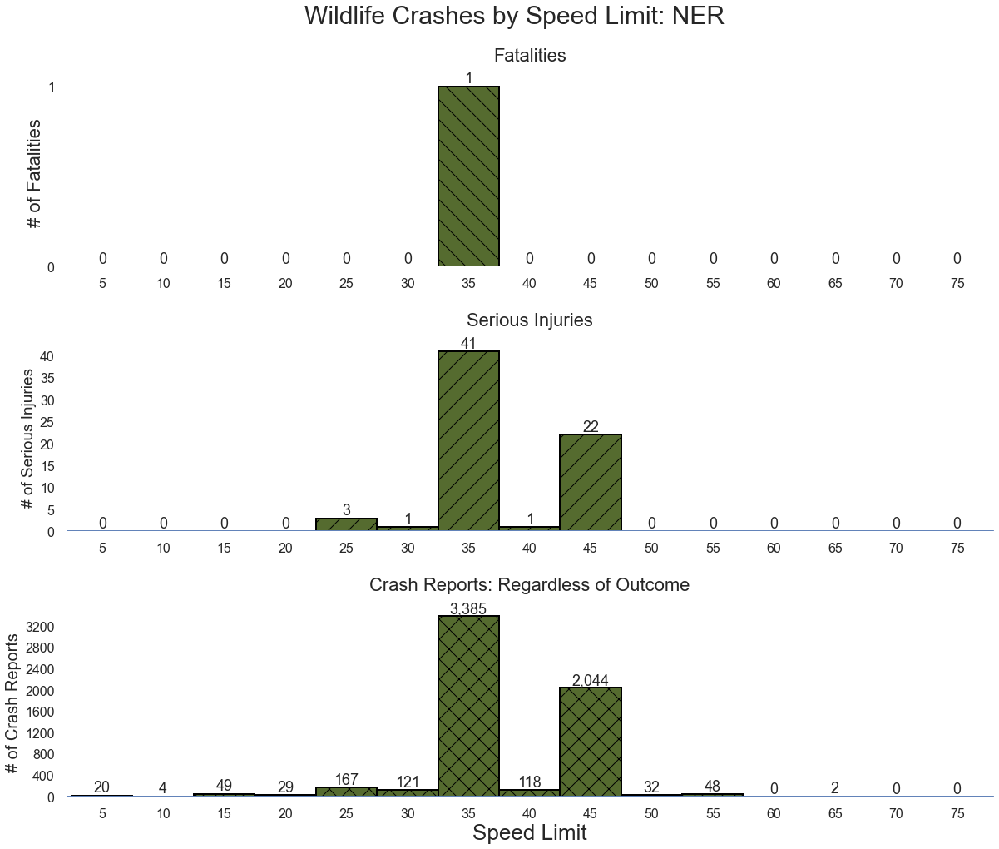

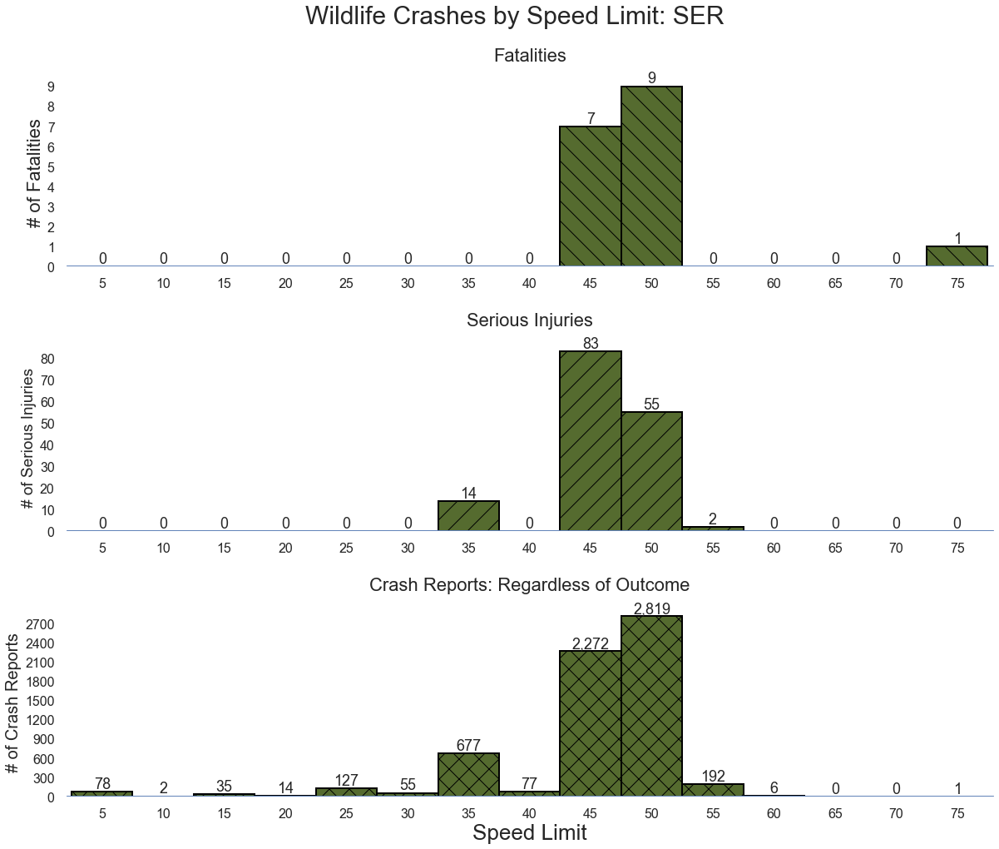

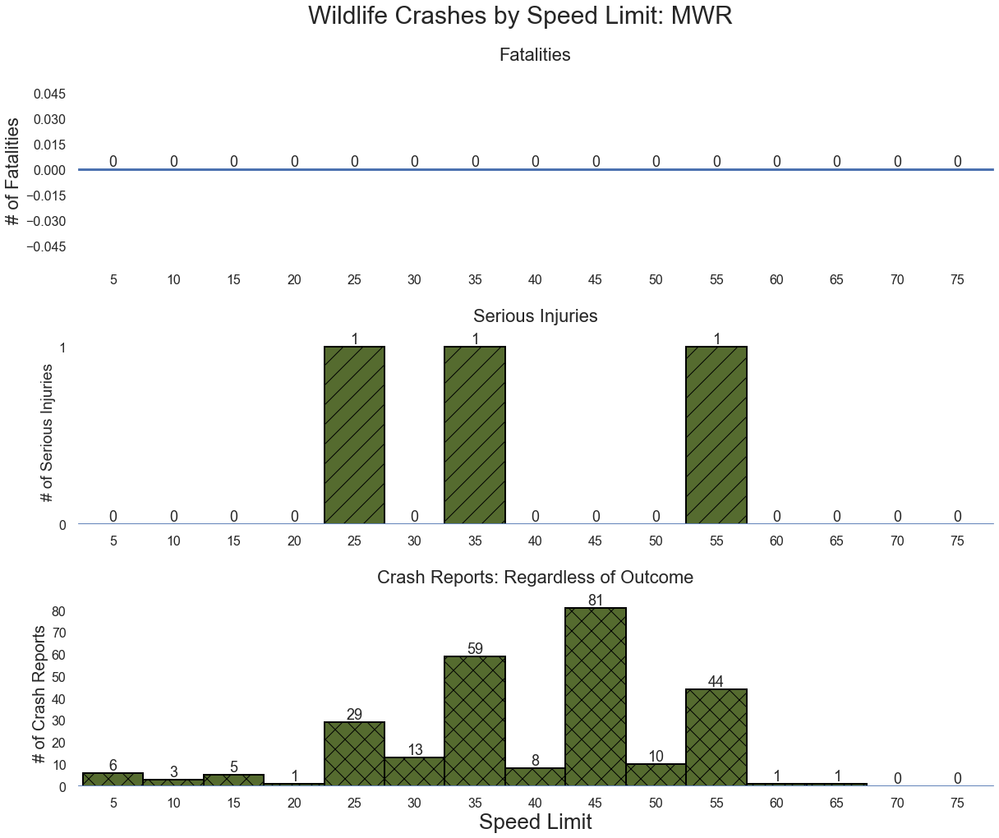

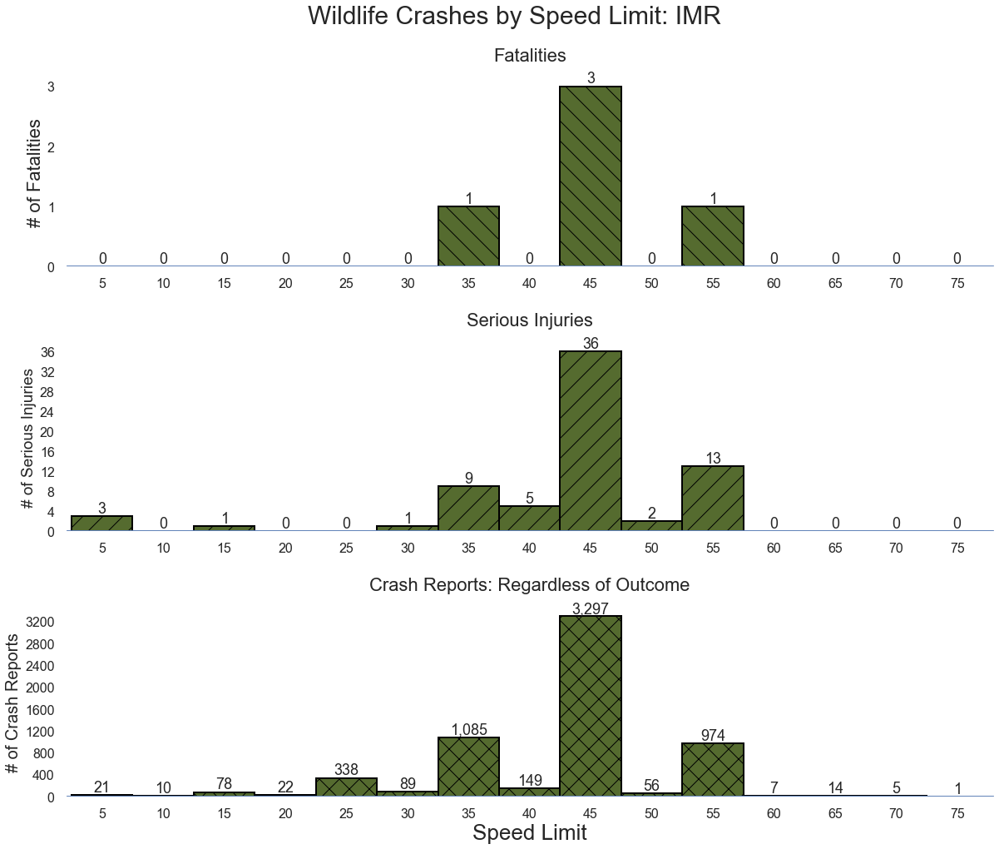

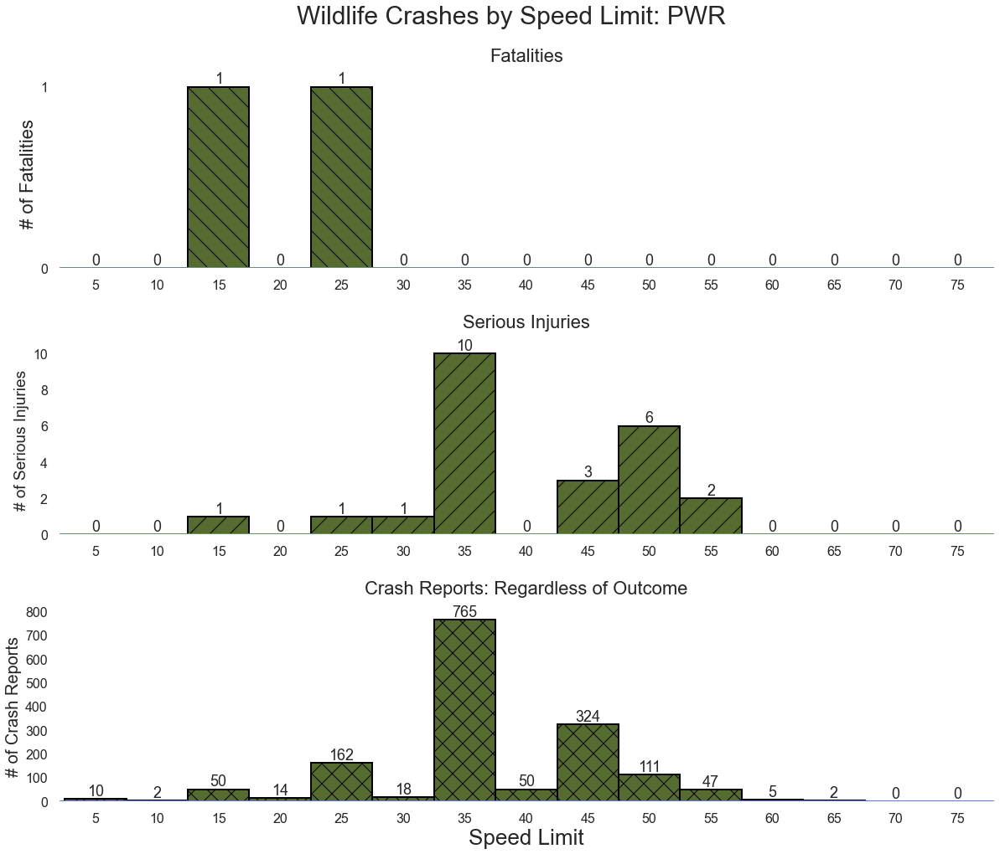

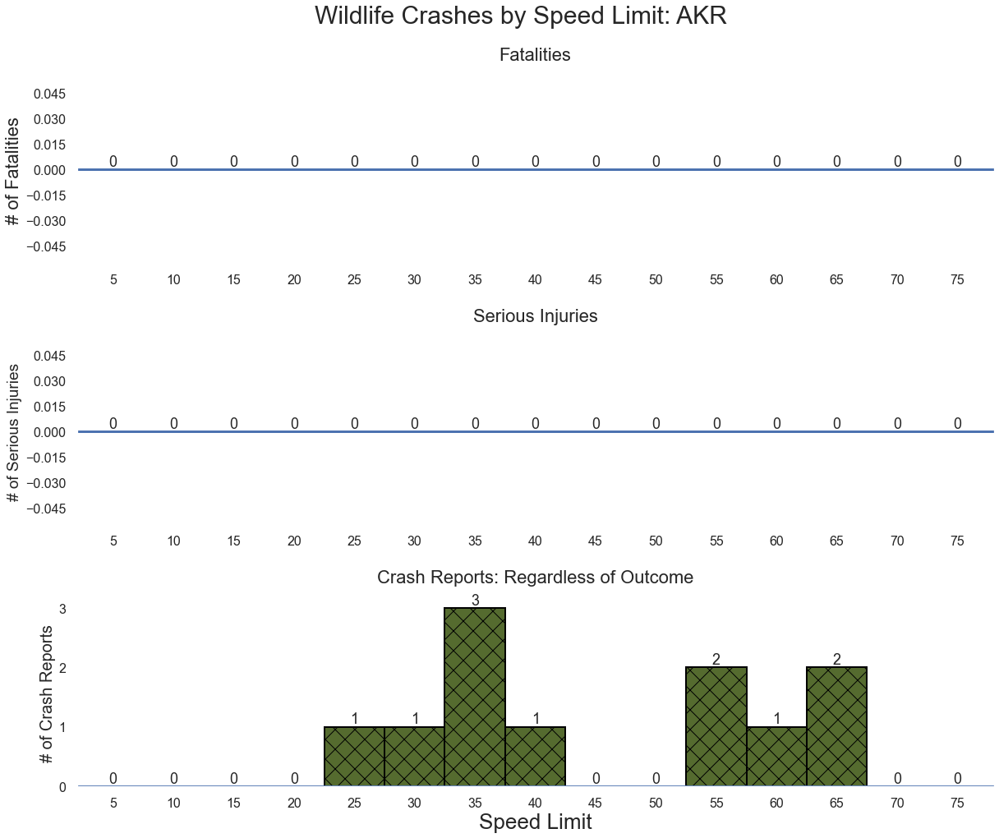

In [80]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    create_posted_speed_fig_animals(region)

### Wildlife Crash Outcomes by Park

In [35]:
def create_wildlife_crashes_table_park(region):
    region = analysis_2024.loc[analysis_2024['RGN']==region]
    animal_region = region.loc[region['Involving Animal']==1]
    animal_region_slim = animal_region[['Park', 'Fatality', 'Incapacitating Injury']]
    animal_region_parks = animal_region_slim.groupby(by=['Park'], as_index=False).sum()
    animal_region_parks['Number of Fatalities'] = animal_region_parks['Fatality'].astype(int)
    animal_region_parks['Number of Serious Injuries'] = animal_region_parks['Incapacitating Injury'].astype(int)
    animal_region_parks = animal_region_parks.drop(columns={'Fatality', 'Incapacitating Injury'})

    return animal_region_parks

In [37]:
create_wildlife_crashes_table_park("NCR")

,Park,Number of Fatalities,Number of Serious Injuries
0,ANAC,0,0
1,ANTI,0,2
2,BARC,0,0
3,BAWA,0,9
4,CATO,0,1
5,CHOH,0,0
6,CLBA,0,0
7,FOWA,0,0
8,FRDO,0,0
9,GREE,0,0


## Data Quality Tables

### IMARS Data Completeness, Regional and National

In [38]:
def create_data_quality_table_imars(region):
    imars_all = analysis_2024.loc[analysis_2024['database']=="IMARS"]
    imars_all_region = imars_all.loc[imars_all['RGN']==region]
    imars_total_crashes = imars_all.shape[0]
    imars_region_crashes = imars_all_region.shape[0]
    imars_total_missingcords = round(imars_all.loc[imars_all['LATITUDE'].isnull()==True].shape[0]/imars_total_crashes*100,1)
    imars_region_missingcords = round(imars_all_region.loc[imars_all_region['LATITUDE'].isnull()==True].shape[0]/imars_region_crashes*100,1)
    
    final_df = pd.DataFrame({
        "Area":["National", region],
        'Total Number of Crashes': [imars_total_crashes, imars_region_crashes], 
        "Missing Coordinates Percentage": [str(imars_total_missingcords) + "%", str(imars_region_missingcords) + "%"]
    })
    
    return final_df

In [40]:
create_data_quality_table_imars("NCR")

,Area,Total Number of Crashes,Missing Coordinates Percentage
0,National,24286,47.4%
1,NCR,7824,27.3%


## Yearly count of crashes by database

### Annual Regional Serious Injuries/Fatalities by Data System and Georeference Quality

In [83]:
def make_yearly_crash_fig(region):
    
    # set up dataframes for plotting
    
    # all data
    df = analysis_2024.loc[analysis_2024['RGN']==region]
    goodyears = df.loc[df['YEAR'].isin(range(1988,2025))]
    imars_all_year = goodyears.loc[goodyears['database']=="IMARS"].groupby('YEAR')
    cds_all_year = goodyears.loc[goodyears['database']=="CDS"].groupby('YEAR')
    goodyears_coords = goodyears.loc[goodyears['LATITUDE'].notnull()]
    imars_coords_year = goodyears_coords.loc[goodyears_coords['database']=="IMARS"].groupby('YEAR')
    cds_coords_year = goodyears_coords.loc[goodyears_coords['database']=="CDS"].groupby('YEAR')
    
    # serious injuries
    imars_all_year_injuries = imars_all_year['Incapacitating Injury'].sum()
    cds_all_year_injuries = cds_all_year['Incapacitating Injury'].sum()
    imars_coords_year_injuries = imars_coords_year['Incapacitating Injury'].sum()
    cds_coords_year_injuries = cds_coords_year['Incapacitating Injury'].sum()
    
    # fatalities
    imars_all_year_fatalities = imars_all_year['Fatality'].sum()
    cds_all_year_fatalities = cds_all_year['Fatality'].sum()
    imars_coords_year_fatalities = imars_coords_year['Fatality'].sum()
    cds_coords_year_fatalities = cds_coords_year['Fatality'].sum()
    
    # plot fig 1 for Serious Injuries
    plt.style.use('seaborn')
    tick_spacing = 2 
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig,ax = plt.subplots(1,1, figsize=(14, 7))

    ax.set_title('Annual Serious Injuries by Data System and Georeference Quality: ' + region, fontsize=20)
    ax.fill_between(cds_all_year_injuries.index, cds_all_year_injuries, label = 'CDS', facecolor = "steelblue")
    ax.fill_between(cds_coords_year_injuries.index, cds_coords_year_injuries, label = 'CDS with lat/long coordinates', hatch = '/', facecolor = "skyblue")
    ax.fill_between(imars_all_year_injuries.index, imars_all_year_injuries, label = 'IMARS', facecolor = "orangered")
    ax.fill_between(imars_coords_year_injuries.index, imars_coords_year_injuries, label = 'IMARS with lat/long coordinates', hatch = "/", facecolor = "darksalmon")

    legend = plt.legend(frameon = 2,fontsize=18)
    frame = legend.get_frame()
    frame.set_color('white')
    frame.set_facecolor('white')
    frame.set_edgecolor('black')
    plt.xlim([1990,2024])
    ax.grid('off')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax.tick_params(axis='x', which='major', labelsize=23, rotation=45)
    ax.tick_params(axis='y', which='major', labelsize=23)
    ax.tick_params(axis='both', which='minor', labelsize=23)
    ax.hlines(0, xmin = 1990, xmax = 2024, linewidth = 1, color = "grey")
    ax.set_xlabel("Year", fontsize=26)
    ax.set_ylabel("Number of Serious Injuries", fontsize=26)

    # plot fig 2 for Fatalities
    plt.style.use('seaborn')
    tick_spacing = 2 
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig,ax = plt.subplots(1,1, figsize=(14, 7))

    ax.set_title('Annual Regional Fatalities by Data System and Georeference Quality: ' + region, fontsize=20)
    ax.fill_between(cds_all_year_fatalities.index, cds_all_year_fatalities, label = 'CDS', facecolor = "steelblue")
    ax.fill_between(cds_coords_year_fatalities.index, cds_coords_year_fatalities, label = 'CDS with lat/long coordinates', hatch = '/', facecolor = "skyblue")
    ax.fill_between(imars_all_year_fatalities.index, imars_all_year_fatalities, label = 'IMARS', facecolor = "orangered")
    ax.fill_between(imars_coords_year_fatalities.index, imars_coords_year_fatalities, label = 'IMARS with lat/long coordinates', hatch = "/", facecolor = "darksalmon")

    legend = plt.legend(frameon = 2,fontsize=18)
    frame = legend.get_frame()
    frame.set_color('white')
    frame.set_facecolor('white')
    frame.set_edgecolor('black')
    plt.xlim([1990,2024])
    ax.grid('off')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax.tick_params(axis='x', which='major', labelsize=23, rotation=45)
    ax.tick_params(axis='y', which='major', labelsize=23)
    ax.tick_params(axis='both', which='minor', labelsize=23)
    ax.hlines(0, xmin = 1990, xmax = 2024, linewidth = 1, color = "grey")
    ax.set_xlabel("Year", fontsize=26)
    ax.set_ylabel("Number of Fatalities", fontsize=26)  

<ipython-input-83-b0fd43c34c51>:27: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-83-b0fd43c34c51>:54: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-83-b0fd43c34c51>:27: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.styl

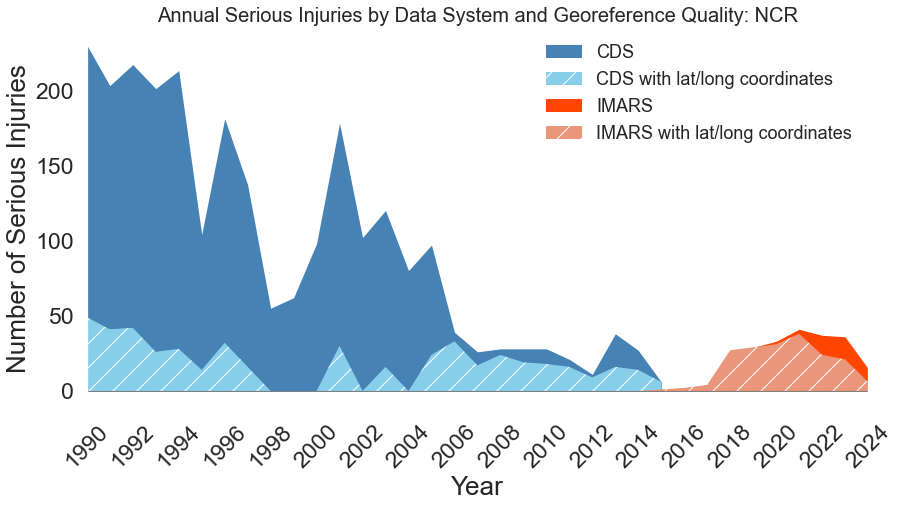

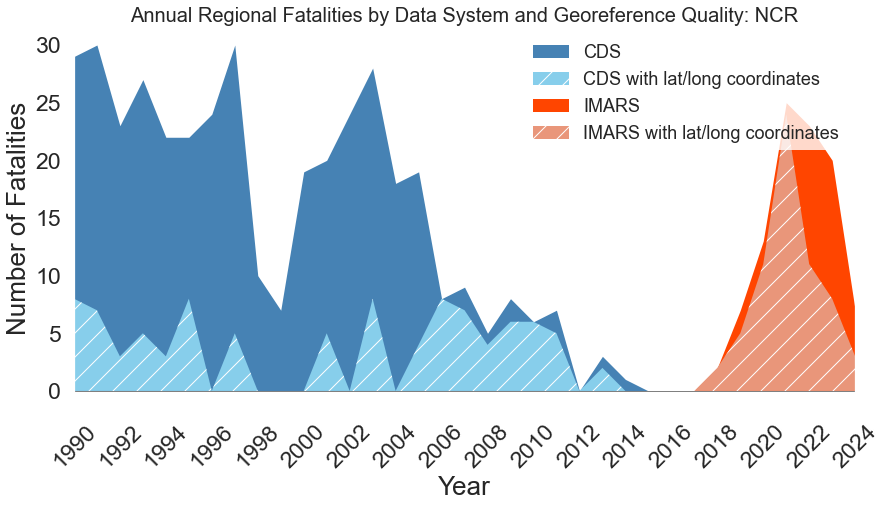

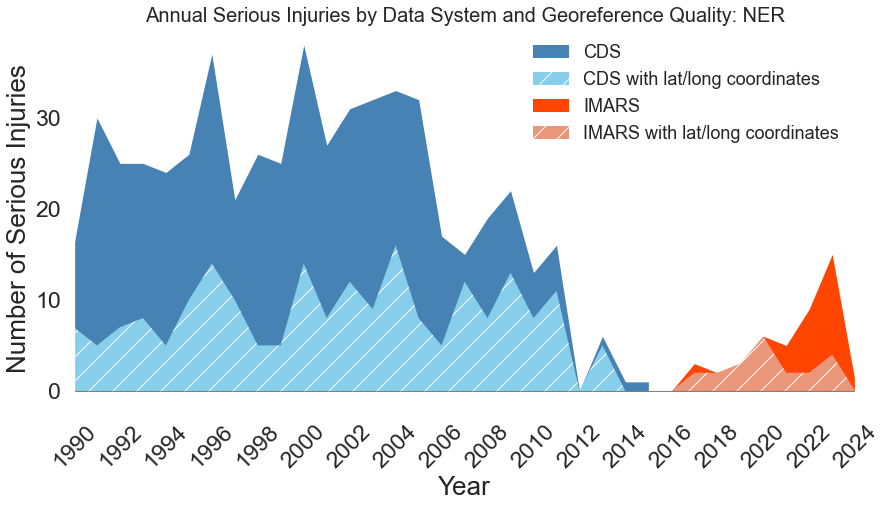

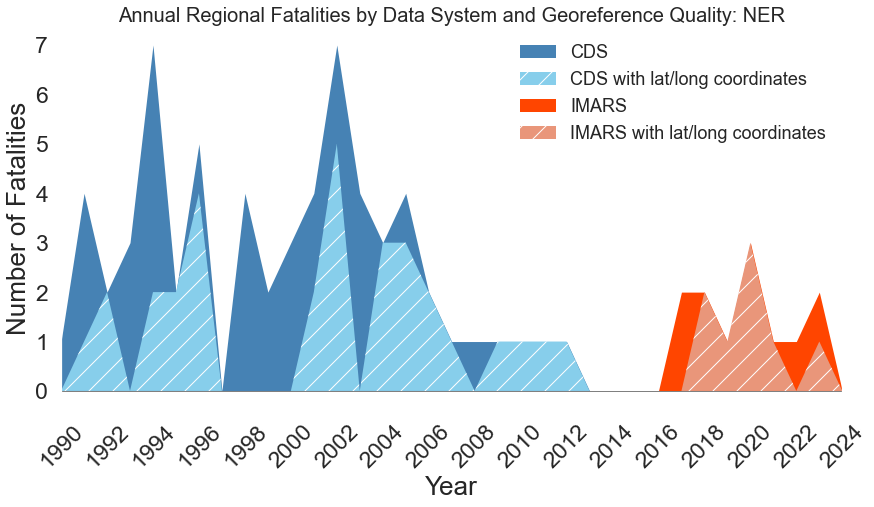

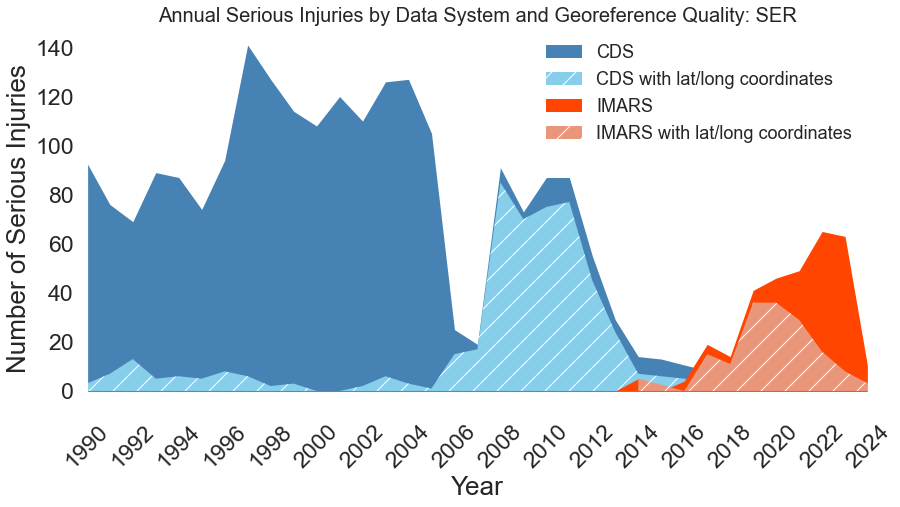

...

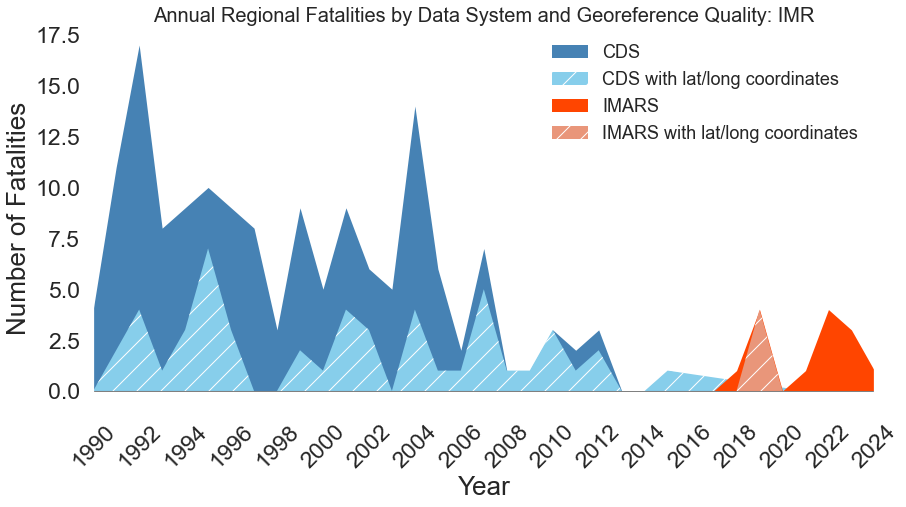

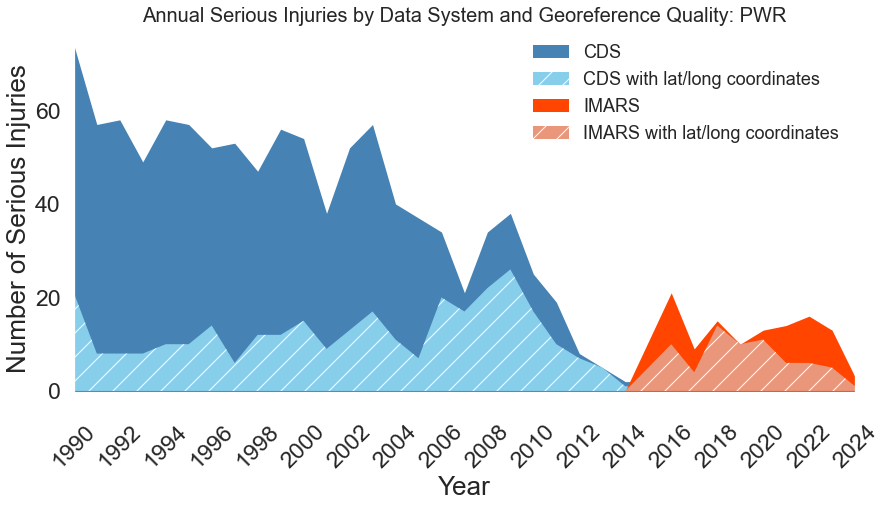

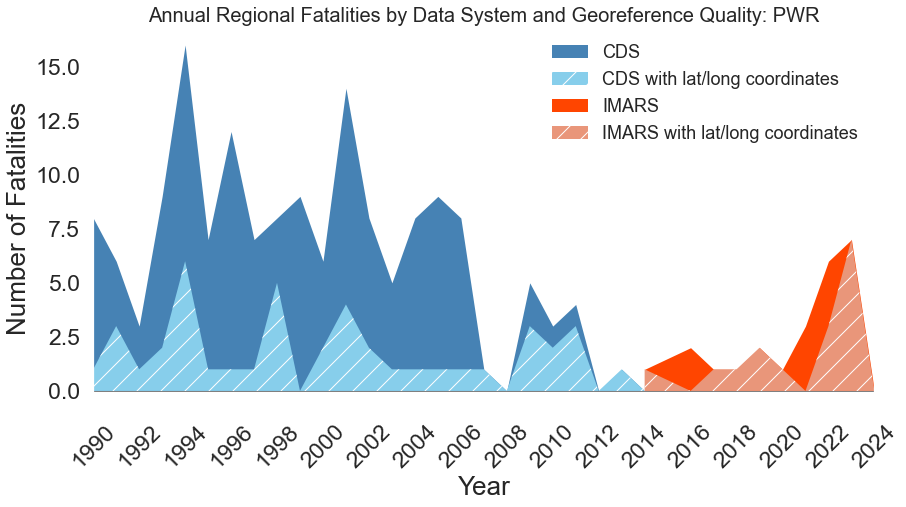

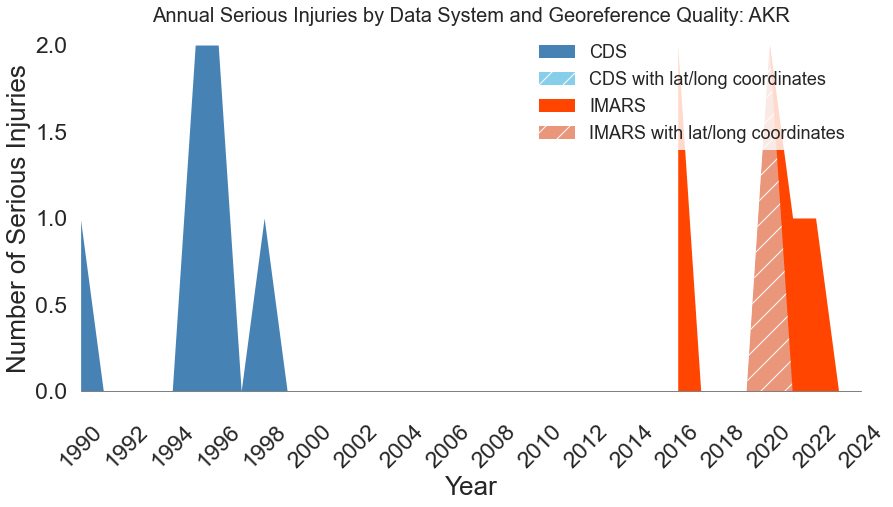

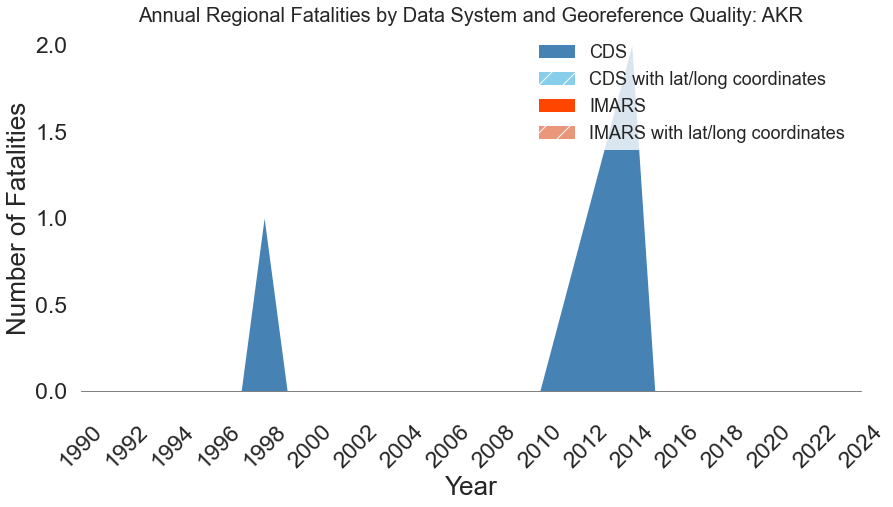

In [84]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    make_yearly_crash_fig(region)

## IMARS geolocation quality assessment

### IMARS Lat/Long Distance from Park Boundary for Top 10 Parks

In [92]:
def make_coordinate_bin_fig(region):
    
    # set up dataframes for plotting
    df = pd.read_excel("./Final Coordinate Stats.xlsx")
    df.columns=["Park","Region","Within Boundary","<1mi Out","1-10mi Out","10-100mi Out",">100mi Out","No Coordinates","Total Crashes"]
    df_region = df.loc[df['Region']==region]
    df_region = df_region.sort_values(by="Total Crashes", ascending=False)
    top10 = pd.DataFrame(df_region.head(10)) # 10 parks with the most crashes in the region
    
    # determine proportion of total crashes for plotting 100% stacked bars
    top10['Within Boundary'] = top10['Within Boundary']/top10['Total Crashes']
    top10["<1mi Out"] = top10["<1mi Out"]/top10['Total Crashes']
    top10["1-10mi Out"] = top10["1-10mi Out"]/top10['Total Crashes']
    top10["10-100mi Out"] = top10["10-100mi Out"]/top10['Total Crashes']
    top10[">100mi Out"] = top10[">100mi Out"]/top10['Total Crashes']
    top10["No Coordinates"] = top10["No Coordinates"]/top10['Total Crashes']
    top10_slim = top10.drop(columns=['Park','Region','Total Crashes'])
    
    # begin plotting
    # Each column will take the sum of all columns before it as its base
    bottom_list = []

    for i in top10_slim.columns:
        b = list(top10_slim.loc[:, top10_slim.columns[0]: i].sum(axis=1))
        bottom_list.append(b)

    fig,ax = plt.subplots(1,1, figsize=(14, 7), dpi=500)
    x_ax = top10['Park']

    patterns = ['','/','','/','','/'] # define hatch for each bin
    colorlist = ['forestgreen','mistyrose', 'lightcoral', 'firebrick', 'maroon', 'slategrey'] # define color for each bin
    for i, v in enumerate(top10_slim.columns):
        if i == 0:
            # First column is at the bottom of the chart so bottom is 0 and doesn't need to be specified.
            plt.bar(x_ax, top10_slim[v], hatch=patterns[i], color=colorlist[i], edgecolor='k')
        else:
            plt.bar(x_ax, top10_slim[v], bottom=bottom_list[i - 1], hatch=patterns[i], color=colorlist[i], edgecolor='k')
    
    ax.tick_params(axis='x', which='major', labelsize=15)
    y_vals = ax.get_yticks()
    ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)
    ax.set_ylabel("Percent of Total IMARS Crashes", fontsize=18)
    ax.set_xlabel("Park", fontsize=18)
    ax.axhline(y=0, color='k')
    
    within_patch = mpatches.Patch(hatch=patterns[0], facecolor=colorlist[0], edgecolor="black", label=top10_slim.columns[0])
    one_mile_patch = mpatches.Patch(hatch=patterns[1], facecolor=colorlist[1], edgecolor="black", label=top10_slim.columns[1])
    ten_mile_patch = mpatches.Patch(hatch=patterns[2], facecolor=colorlist[2], edgecolor="black", label=top10_slim.columns[2])
    hundred_mile_patch = mpatches.Patch(hatch=patterns[3], facecolor=colorlist[3], edgecolor="black", label=top10_slim.columns[3])
    over_hundred_mile_patch = mpatches.Patch(hatch=patterns[4], facecolor=colorlist[4], edgecolor="black", label=top10_slim.columns[4])
    no_coords_patch = mpatches.Patch(hatch=patterns[5], facecolor=colorlist[5], edgecolor="black", label=top10_slim.columns[5])
    ax.legend(loc="upper left", frameon=1,bbox_to_anchor=(0.95, 1), prop={'size': 15}, handles = [within_patch, one_mile_patch, ten_mile_patch, hundred_mile_patch, over_hundred_mile_patch, no_coords_patch])
    ax.set_title('IMARS Lat/Long Distance from Park Boundary for Top 10 Parks: ' + region, fontsize=22)
    
    plt.show()

<ipython-input-92-181c09d2df16>:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


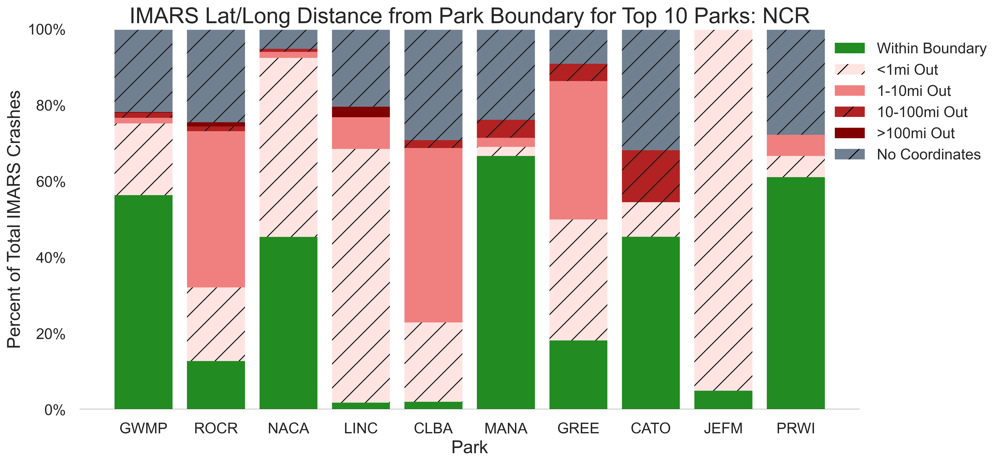

<ipython-input-92-181c09d2df16>:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


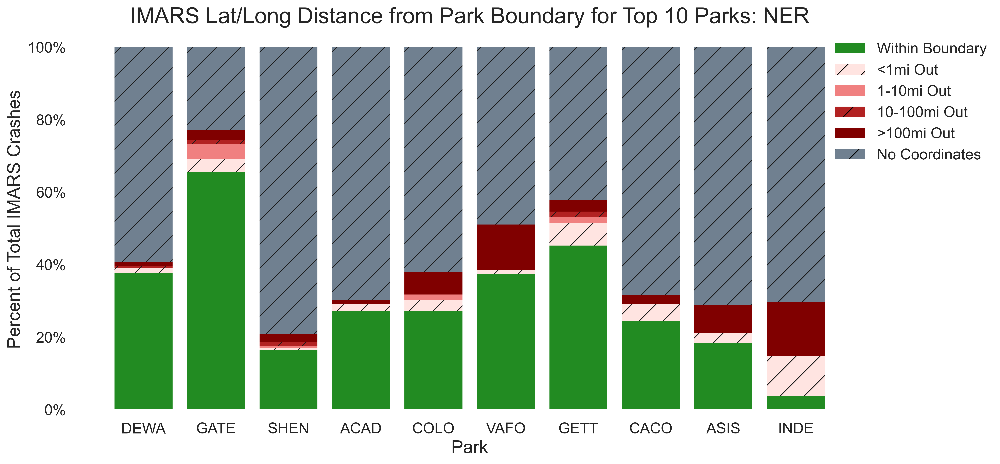

<ipython-input-92-181c09d2df16>:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


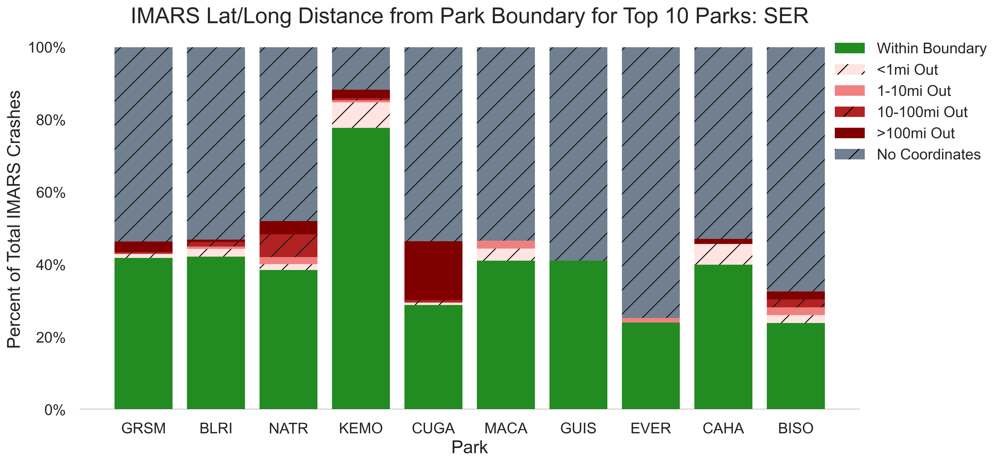

<ipython-input-92-181c09d2df16>:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


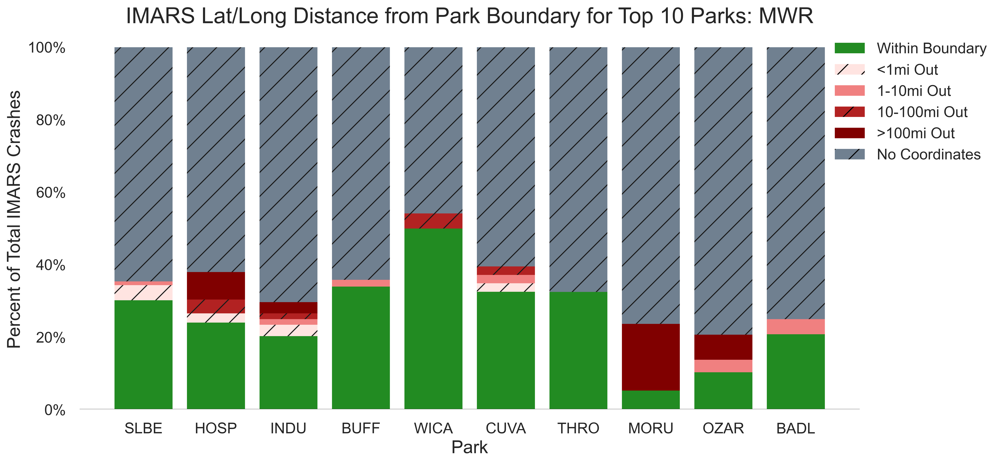

<ipython-input-92-181c09d2df16>:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


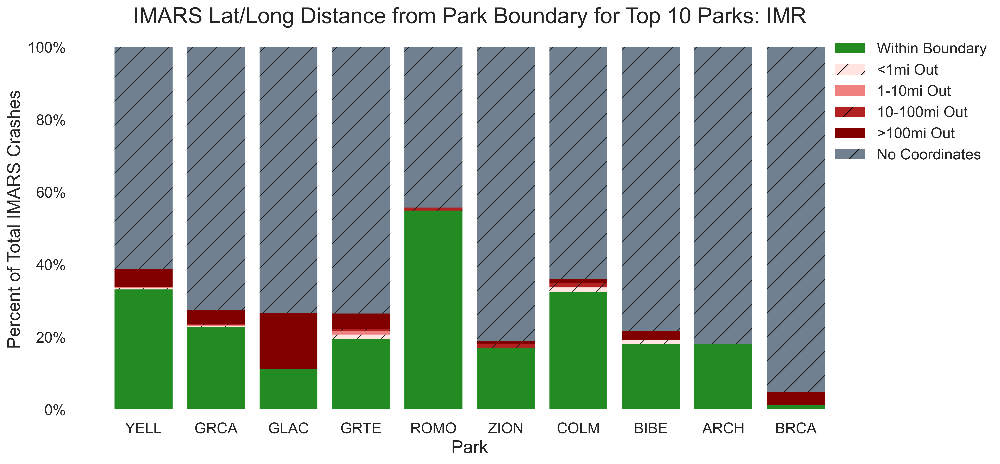

<ipython-input-92-181c09d2df16>:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


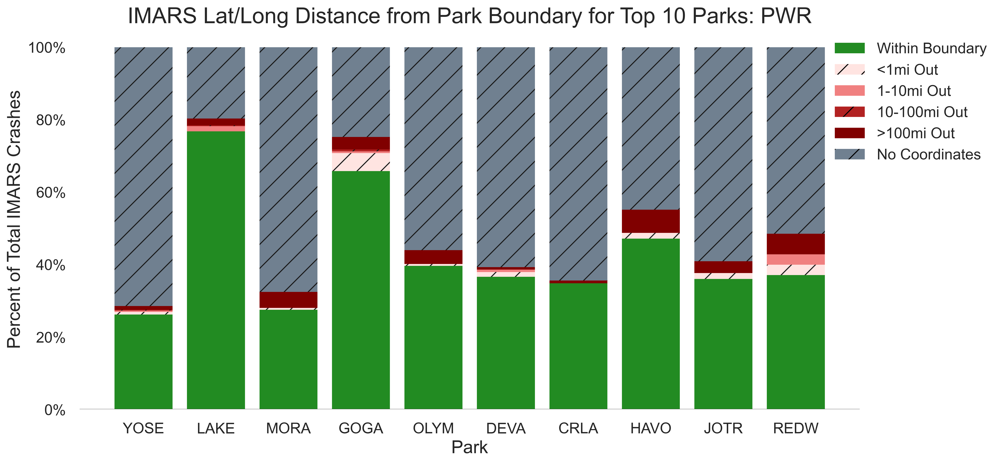

<ipython-input-92-181c09d2df16>:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(['{:.0%}'.format(y) for y in y_vals], fontsize=15)


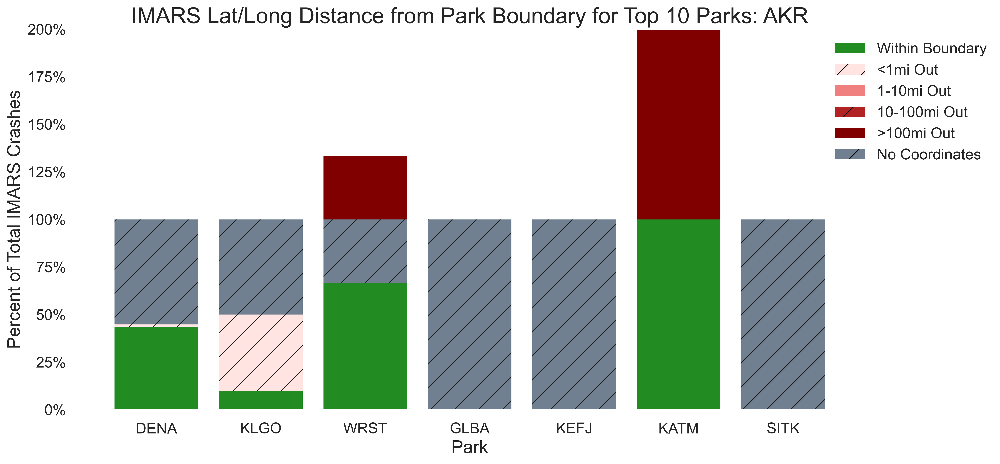

In [93]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    make_coordinate_bin_fig(region)

## VRU crashes

### Crashes Involving VRUs, Regional and National 

In [63]:
def create_vru_crashes_table(region):
    inj_or_fatal = analysis_2024.loc[analysis_2024['Crash_Severity'].isin(["Fatal","Incap"])]
    vru_inj_or_fatal = inj_or_fatal.loc[inj_or_fatal['VRU']==1]
    rgn = analysis_2024.loc[analysis_2024['RGN']==region]
    vru = analysis_2024.loc[analysis_2024['VRU']==1]
    vru_region = vru.loc[vru['RGN']==region]
    vru_inj_or_fatal_region = vru_inj_or_fatal.loc[vru_inj_or_fatal['RGN']==region]
    vru_percent_region = round(vru_region.shape[0]/rgn.shape[0]*100,2)
    vru_inj_or_fatal_percent_region = round(vru_inj_or_fatal_region.shape[0]/vru_region.shape[0]*100,2)
    vru_serious_injury_region = int(vru_region['Incapacitating Injury'].sum())
    vru_fatals_region = int(vru_region['Fatality'].sum())
        
    vru_percent = round(vru.shape[0]/analysis_2024.shape[0]*100,2)
    vru_inj_or_fatal_percent = round(vru_inj_or_fatal.shape[0]/vru.shape[0]*100,2)
    vru_serious_injury = int(vru['Incapacitating Injury'].sum())
    vru_fatals = int(vru['Fatality'].sum())
    
    df_final = pd.DataFrame({
    "Fields": ["Percent of Total Crashes", "Percent of VRU Crashes that Resulted in a Serious Injury/Fatality", "Number of Serious Injuries", "Number of Fatalities"],
    region: [str(vru_percent_region) + "%", str(vru_inj_or_fatal_percent_region) + "%", vru_serious_injury_region, vru_fatals_region], 
    "National": [str(vru_percent) + "%", str(vru_inj_or_fatal_percent) + "%", vru_serious_injury, vru_fatals]
     })
    
    return df_final

In [64]:
create_vru_crashes_table("NCR")

,Fields,NCR,National
0,Percent of Total Crashes,1.15%,1.0%
1,Percent of VRU Crashes that Resulted in a Seri...,19.45%,19.02%
2,Number of Serious Injuries,185,393
3,Number of Fatalities,39,52


### VRU Crash Outcomes by Park

In [54]:
def create_vru_crashes_table_park(region):
    # create dataframe for number of serious injuries and fatalities in VRU crashes, number of VRU crashes that resulted in an injury or fatality by park   
    region = analysis_2024.loc[analysis_2024['RGN']==region]
    vru_region = region.loc[region['VRU']==1]
    vru_region_slim = vru_region[['Park', 'Fatality', 'Incapacitating Injury']]
    vru_region_parks = vru_region_slim.groupby(by=['Park'], as_index=False).sum()
    vru_region_parks['Number of Fatalities'] = vru_region_parks['Fatality'].astype(int)
    vru_region_parks['Number of Serious Injuries'] = vru_region_parks['Incapacitating Injury'].astype(int)
    vru_region_parks = vru_region_parks.drop(columns={'Fatality','Incapacitating Injury'})

    return vru_region_parks

In [55]:
create_vru_crashes_table_park("NCR")

,Park,Number of Fatalities,Number of Serious Injuries
0,BAWA,20,24
1,CHOH,0,6
2,FOWA,0,0
3,GREE,0,0
4,GWMP,6,31
5,JOFK,0,1
6,KEPA,0,0
7,MLND,0,0
8,MRLT,0,0
9,NACA,0,0


### VRU crashes by Speed Limit

In [88]:
def create_posted_speed_fig_vrus(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2024.loc[analysis_2024['RGN']==region]   
    speed_list = [5,10,15,20,25,30,35,40,45,50,55,60,65,70,75]
    speed_columns = ['5_mph', '10_mph', '15_mph', '20_mph', '25_mph','30_mph', '35_mph', '40_mph', '45_mph', '50_mph', '55_mph', '60_mph','65_mph', '70_mph', '75_mph']
    vru = df.loc[df['VRU']==1]
    vru_fatalities = []
    vru_serious_injuries = []
    vru_crashes = []

    for i in speed_columns:
        num_vru_fatalities = vru.loc[vru[i]==1]['Fatality'].sum()
        vru_fatalities.append(num_vru_fatalities)
        num_vru_serious_injuries = vru.loc[vru[i]==1]['Incapacitating Injury'].sum()
        vru_serious_injuries.append(num_vru_serious_injuries)    
        num_vru_crashes = vru.loc[vru[i]==1].shape[0]
        vru_crashes.append(num_vru_crashes)
        
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    tick_spacing = 5
    fig.suptitle('VRU Crashes by Speed Limit: ' + region, fontsize=30)

    # subplot data
    ax[0].bar(speed_list, vru_fatalities, width = 5, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[1].bar(speed_list, vru_serious_injuries, width = 5, hatch = "/", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[2].bar(speed_list, vru_crashes, width = 5, hatch = "x", color = 'sienna', edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    ax[0].set_xlim([2, 78])
    ax[0].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[0].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].tick_params(axis='x', which='major', labelsize=16)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    ax[1].set_xlim([2, 78])
    ax[1].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[1].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=16)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    ax[2].set_xlim([2, 78])
    ax[2].hlines(0, xmin = 0, xmax = 78, linewidth = 3)
    ax[2].xaxis.set_major_locator(ticker.MultipleLocator(tick_spacing))
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Speed Limit',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=16)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

<ipython-input-88-11ff24915219>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-88-11ff24915219>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-88-11ff24915219>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.styl

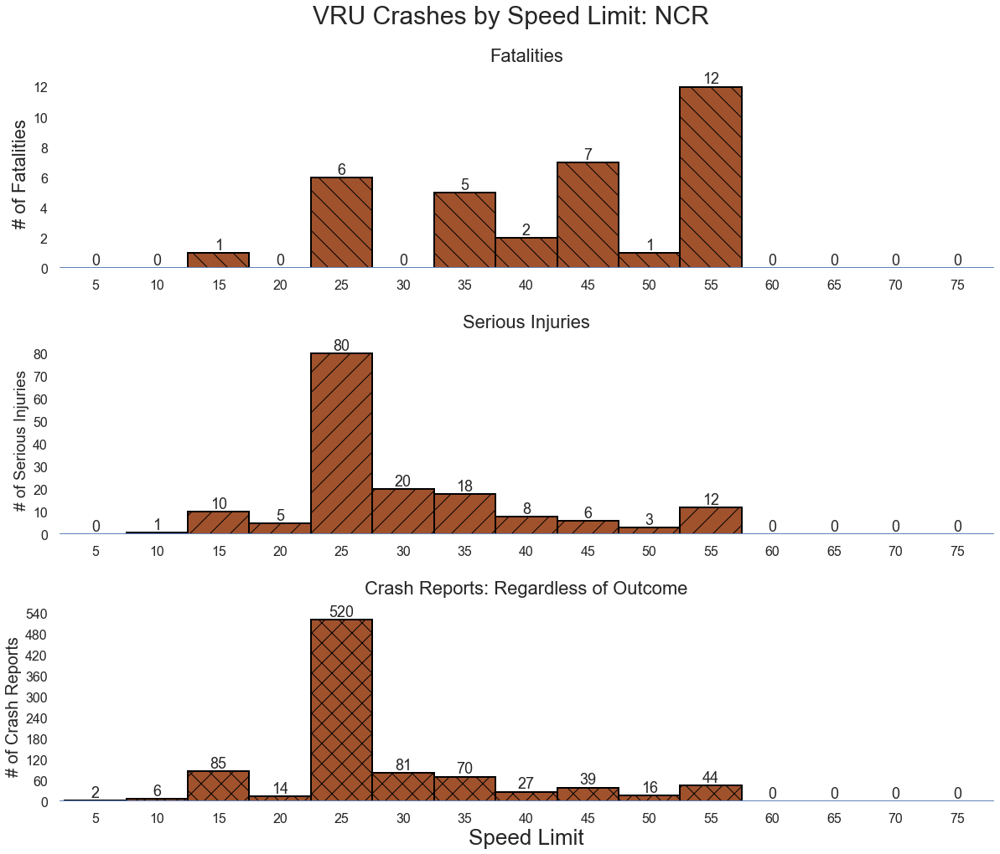

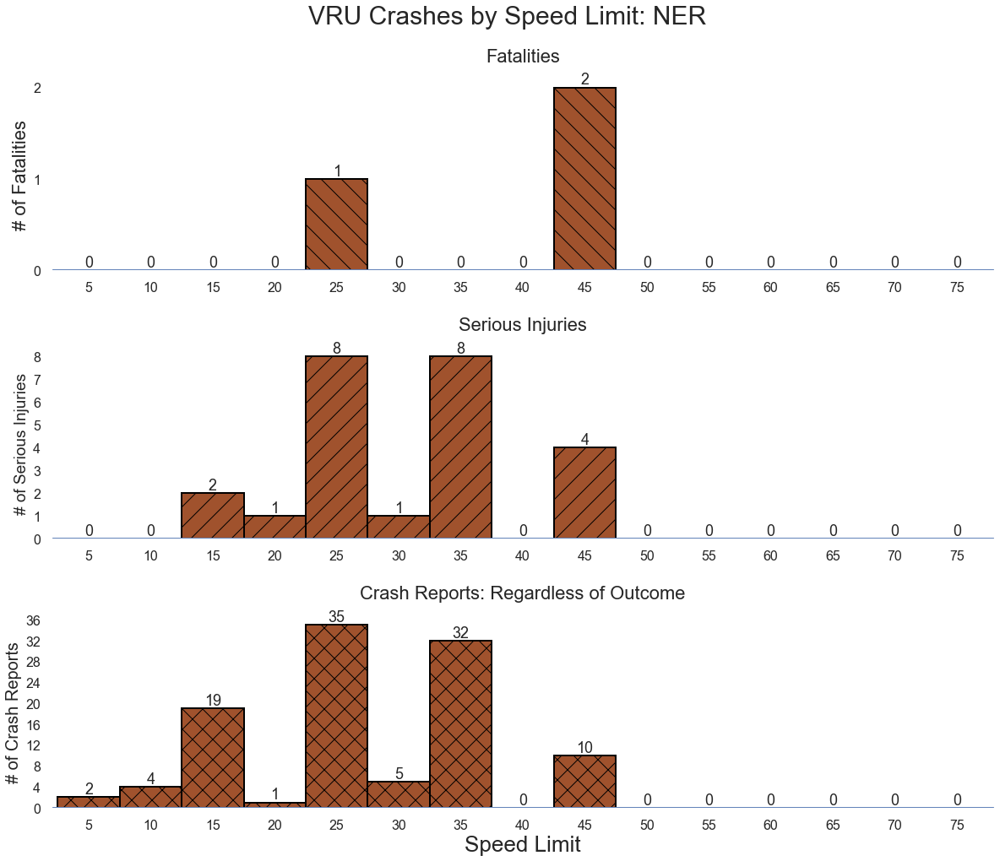

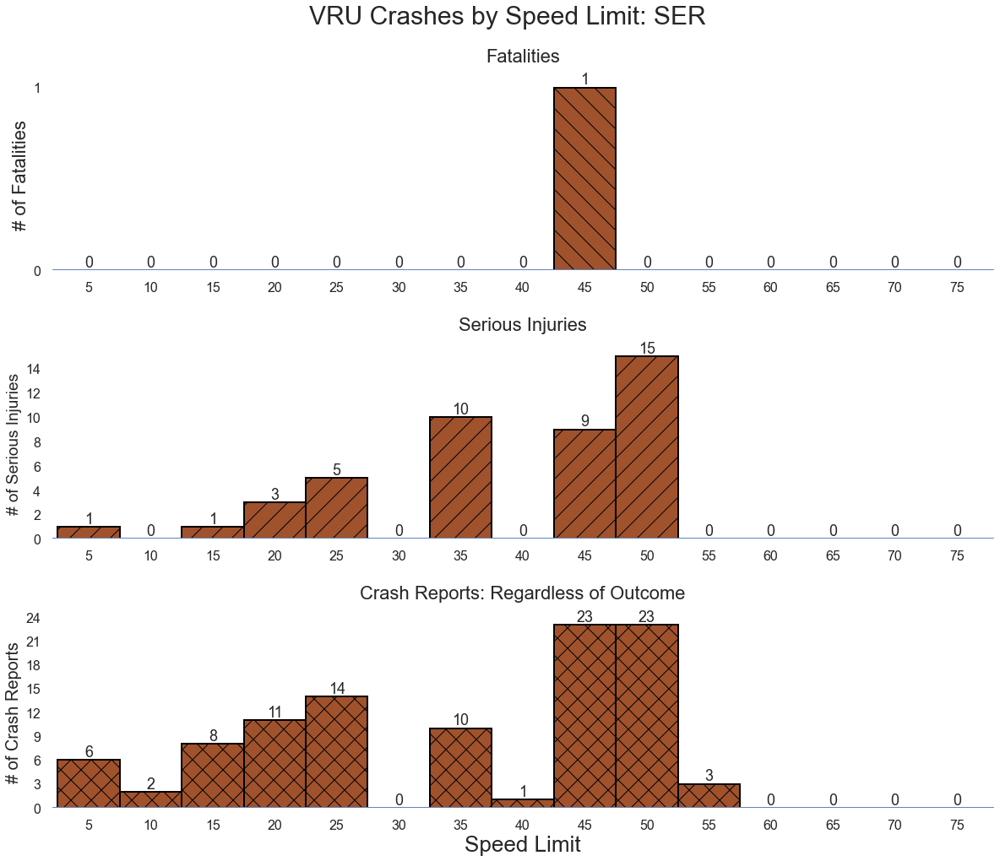

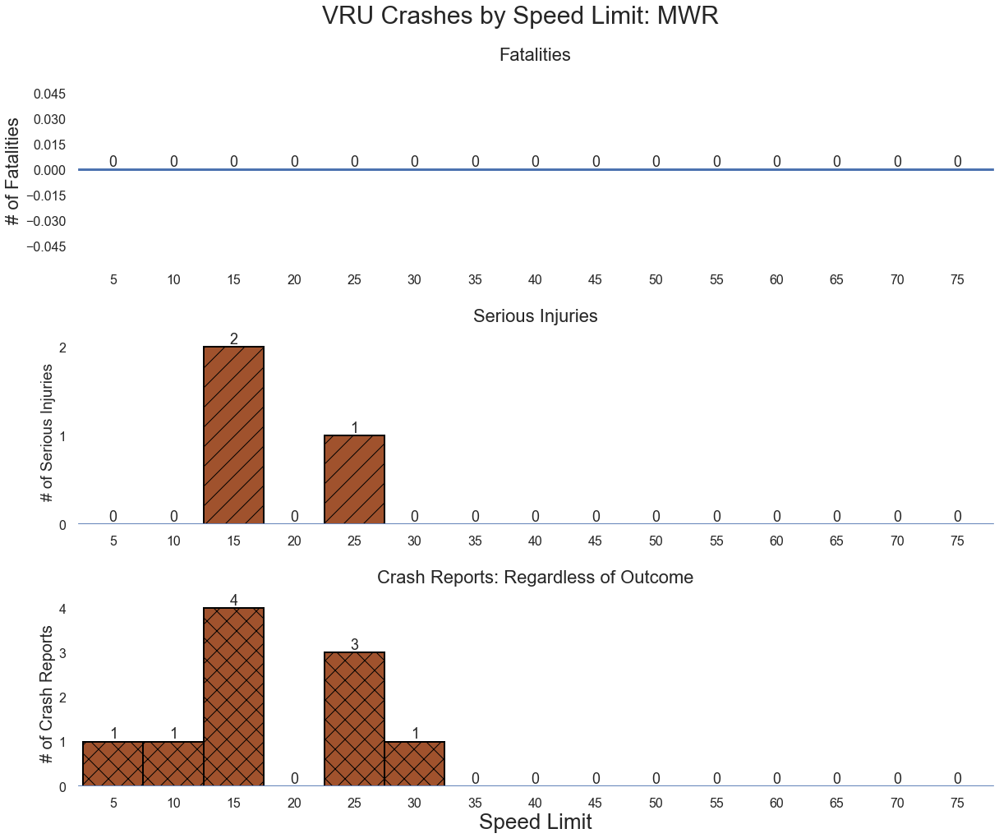

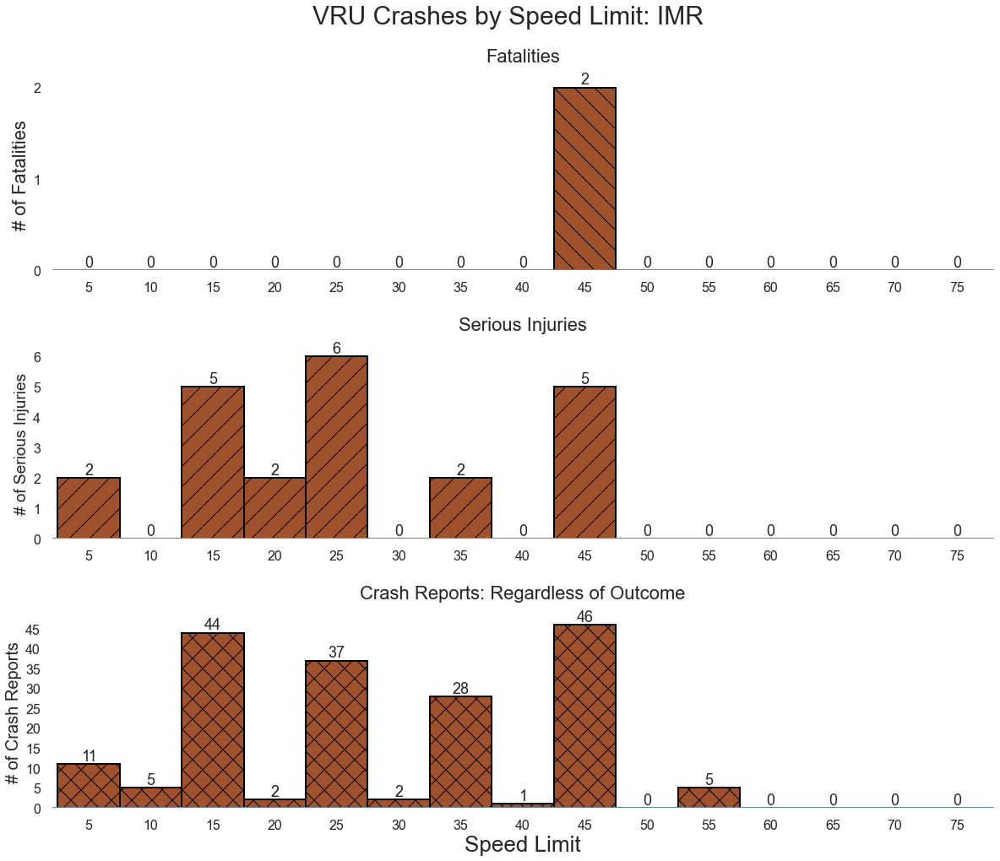

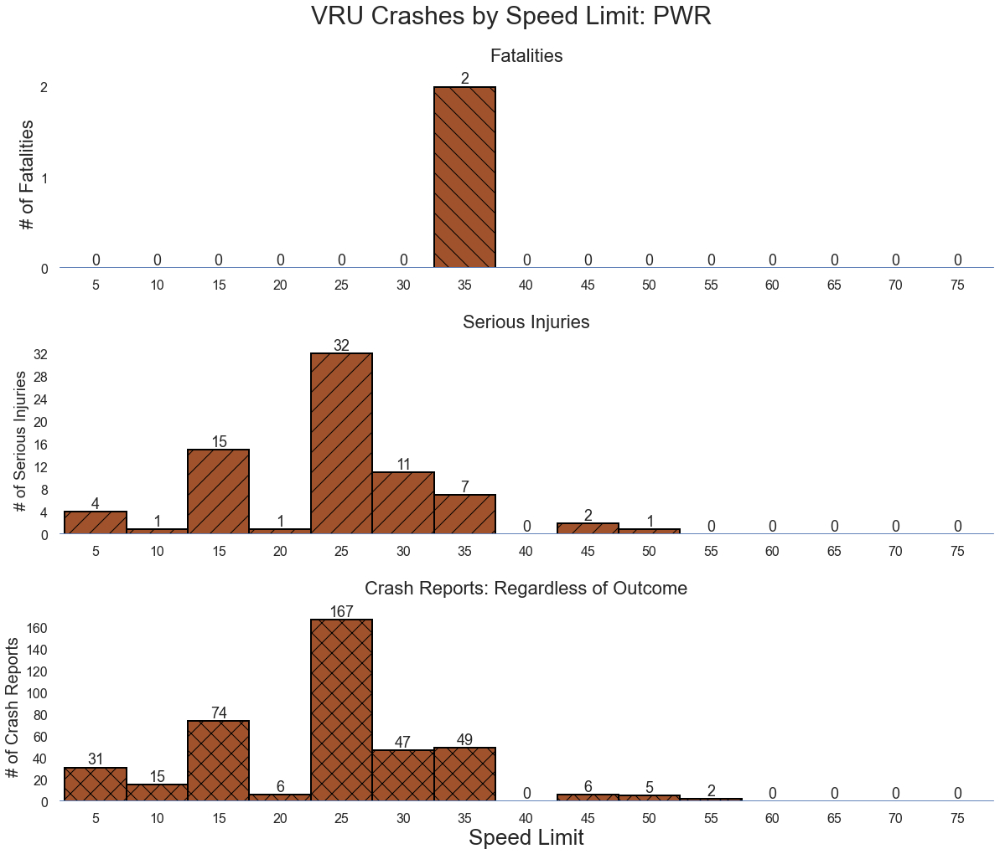

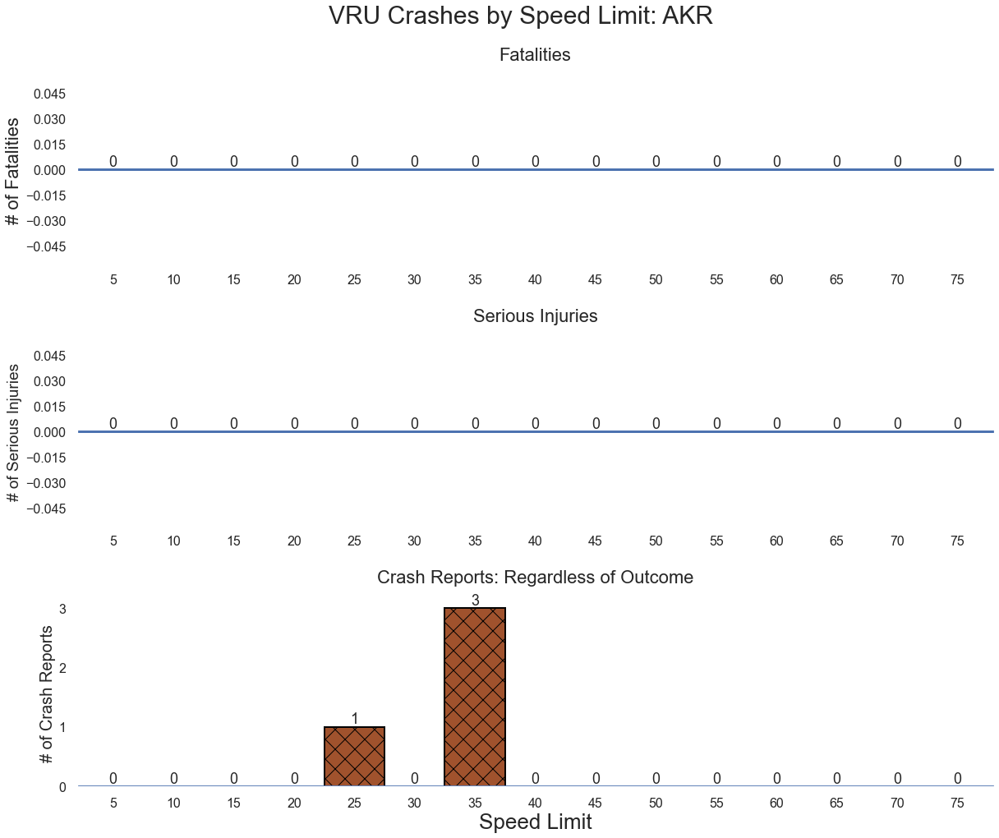

In [89]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    create_posted_speed_fig_vrus(region)

### VRU crashes by Location

In [90]:
def create_location_fig_vrus(region):
    from matplotlib.ticker import MaxNLocator
    df = analysis_2024.loc[analysis_2024['RGN']==region]   
    crosswalks = ['Crosswalk','Outside a Crosswalk']
    vru = df.loc[df['VRU']==1]
    vru_crosswalk_fatalities = []
    vru_crosswalk_serious_injuries = []
    vru_crosswalk_crashes = []

    for i in crosswalks:
        num_vru_crosswalk_fatalities = vru.loc[vru[i]==1]['Fatality'].sum()
        vru_crosswalk_fatalities.append(num_vru_crosswalk_fatalities)
        num_vru_crosswalk_serious_injuries = vru.loc[vru[i]==1]['Incapacitating Injury'].sum()
        vru_crosswalk_serious_injuries.append(num_vru_crosswalk_serious_injuries)    
        num_vru_crosswalk_crashes = vru.loc[vru[i]==1].shape[0]
        vru_crosswalk_crashes.append(num_vru_crosswalk_crashes)

    # set up main figure with three subplots
    plt.style.use('seaborn')
    sns.set(rc={'axes.facecolor':'1', 'figure.facecolor':'white', 'patch.linewidth': 0.0})
    fig, ax = plt.subplots(3,1,figsize=(20,15))
    fig.suptitle('VRU Crashes by Crash Location: ' + region, fontsize=30)

    # subplot data
    ax[0].bar(crosswalks, vru_crosswalk_fatalities, hatch = "\\", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[1].bar(crosswalks, vru_crosswalk_serious_injuries, hatch = "/", color = 'sienna', edgecolor = "black", linewidth=2)
    ax[2].bar(crosswalks, vru_crosswalk_crashes, hatch = "x", color = 'sienna', edgecolor = "black", linewidth=2)

    # annotate all plots with bar totals
    rects = ax[0].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[0].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[1].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[1].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    rects = ax[2].patches
    labels = [f"label{i}" for i in range(len(rects))]
    for rect, label in zip(rects, labels):
        height = rect.get_height()
        label = '{:,}'.format(int(height))
        ax[2].text(rect.get_x() + rect.get_width() / 2, height, label, ha="center", va="bottom",fontsize=18)

    # format each subplot
    ax[0].set_title("Fatalities",fontsize= 22, pad = 20)
    ax[0].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[0].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[0].set_ylabel("# of Fatalities", fontsize = 22)#ylabel
    ax[0].tick_params(axis='x', which='major', labelsize=22)
    ax[0].tick_params(axis='y', which='major', labelsize=16)
    ax[0].tick_params(axis='both', which='minor', labelsize=8)

    ax[1].set_title("Serious Injuries",fontsize= 22, pad = 20)
    ax[1].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[1].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[1].set_ylabel("# of Serious Injuries", fontsize = 19)#ylabel
    ax[1].tick_params(axis='x', which='major', labelsize=22)
    ax[1].tick_params(axis='y', which='major', labelsize=16)
    ax[1].tick_params(axis='both', which='minor', labelsize=8)

    ax[2].set_title("Crash Reports: Regardless of Outcome",fontsize= 22, pad = 20)
    ax[2].hlines(0, xmin = 0, xmax = 1, linewidth = 3)
    ax[2].yaxis.set_major_locator(MaxNLocator(integer=True))
    ax[2].set_xlabel('Crash Location',fontsize = 26) #xlabel
    ax[2].set_ylabel("# of Crash Reports", fontsize = 20)#ylabel
    ax[2].tick_params(axis='x', which='major', labelsize=22)
    ax[2].tick_params(axis='y', which='major', labelsize=16)
    ax[2].tick_params(axis='both', which='minor', labelsize=8)

    # set the spacing between subplots
    plt.subplots_adjust(bottom=0.1, top=0.9, wspace=0.4, hspace=0.4)

<ipython-input-90-580c27f11964>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-90-580c27f11964>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')
<ipython-input-90-580c27f11964>:19: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.styl

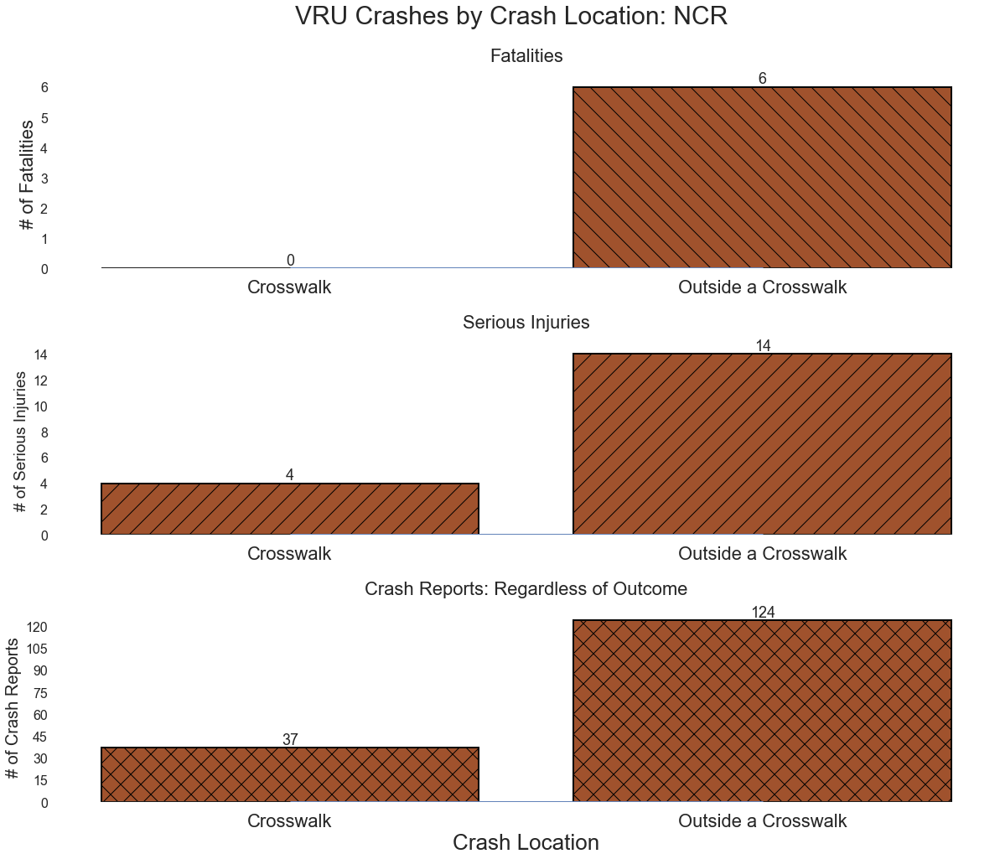

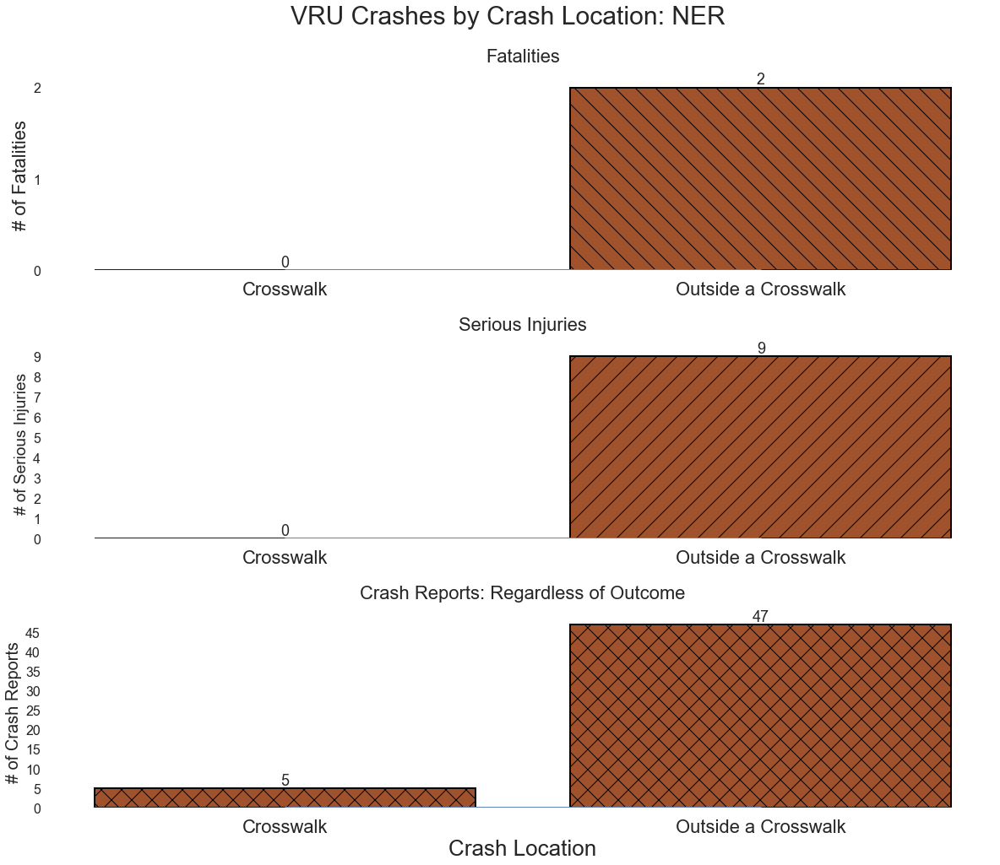

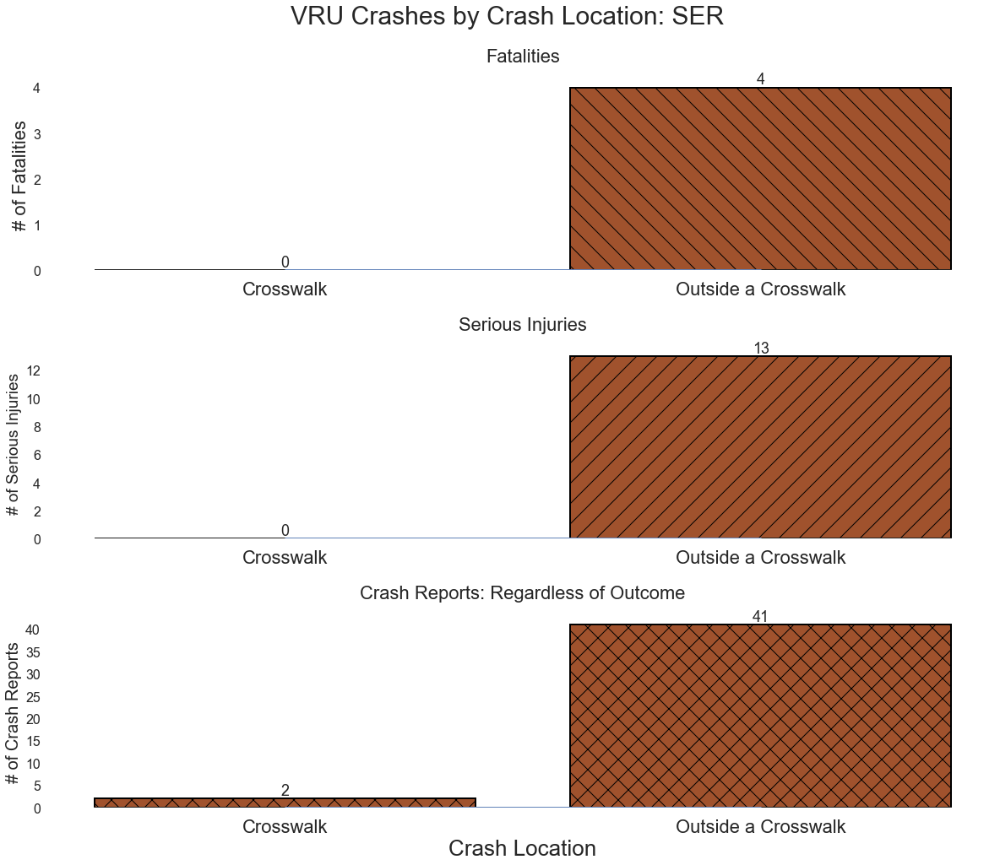

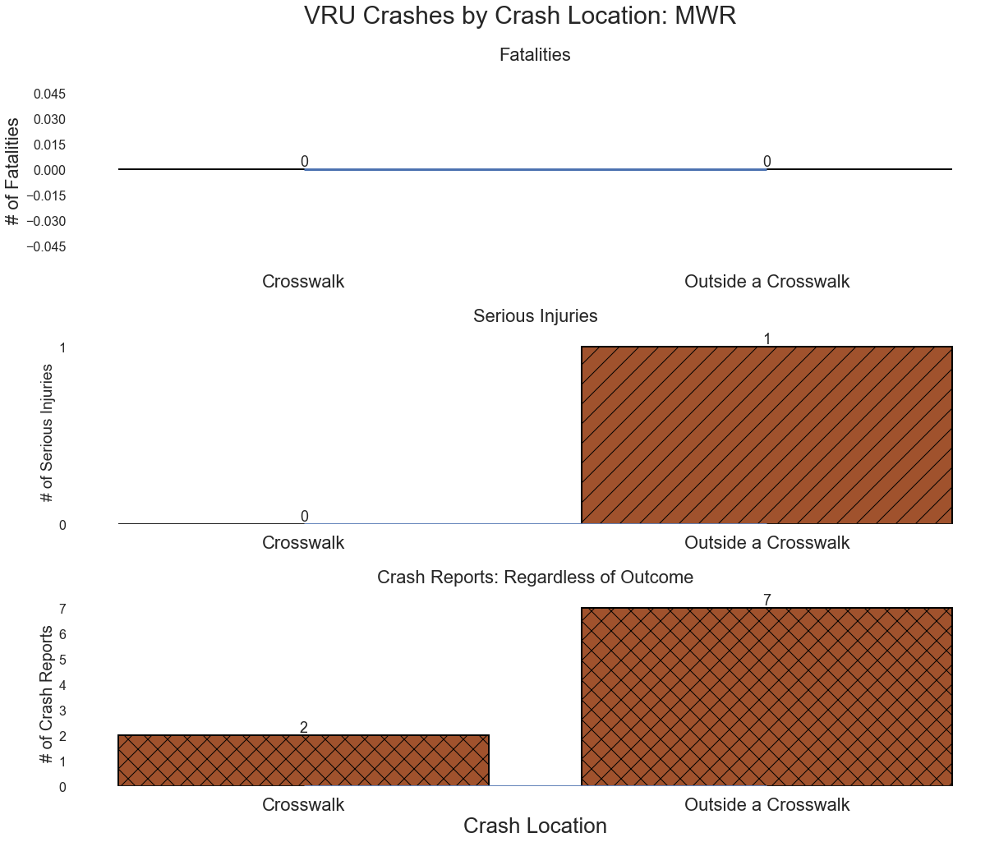

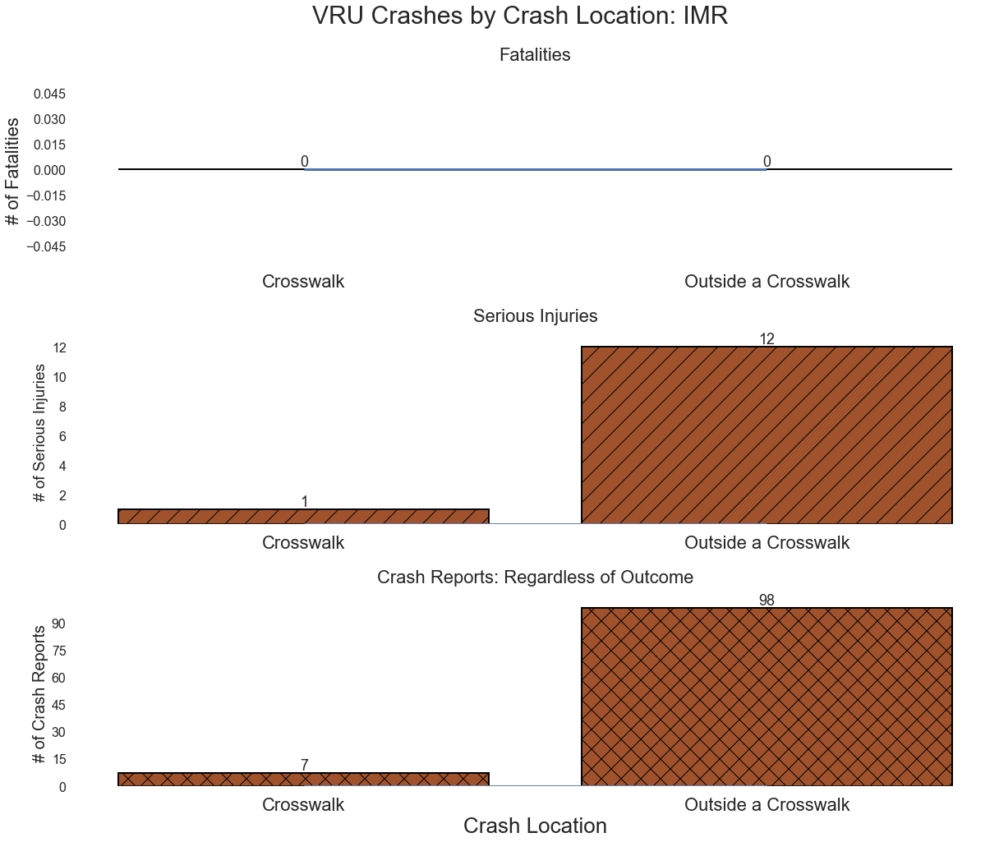

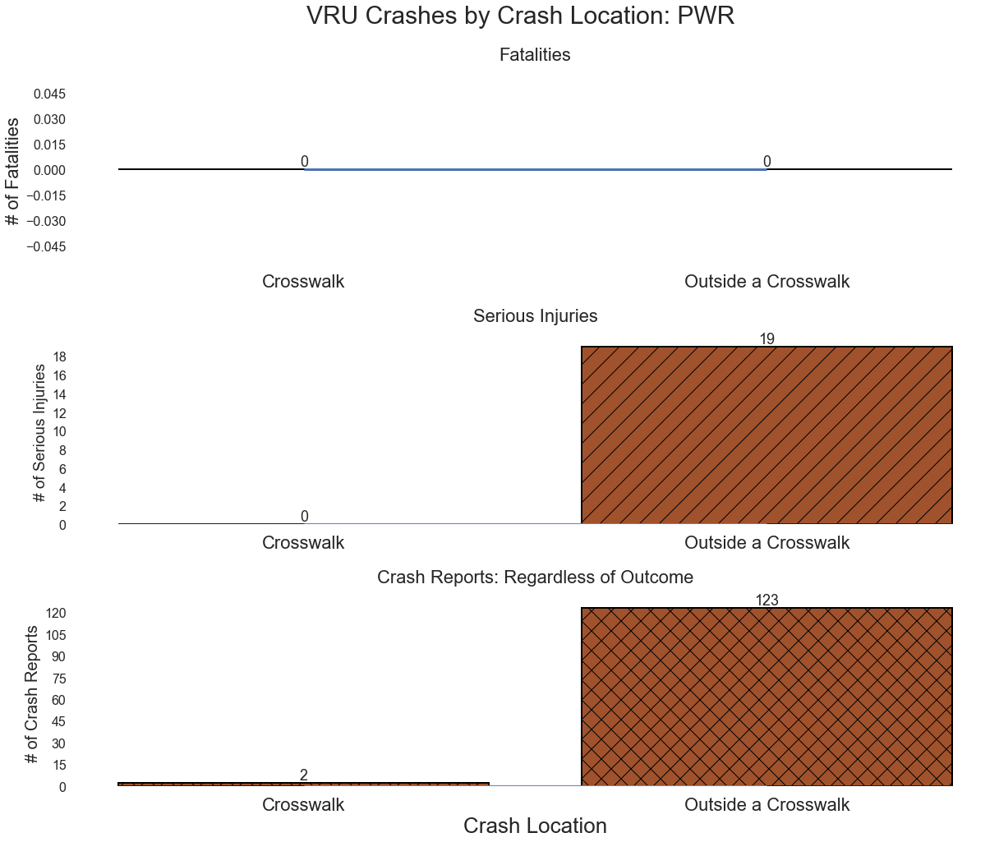

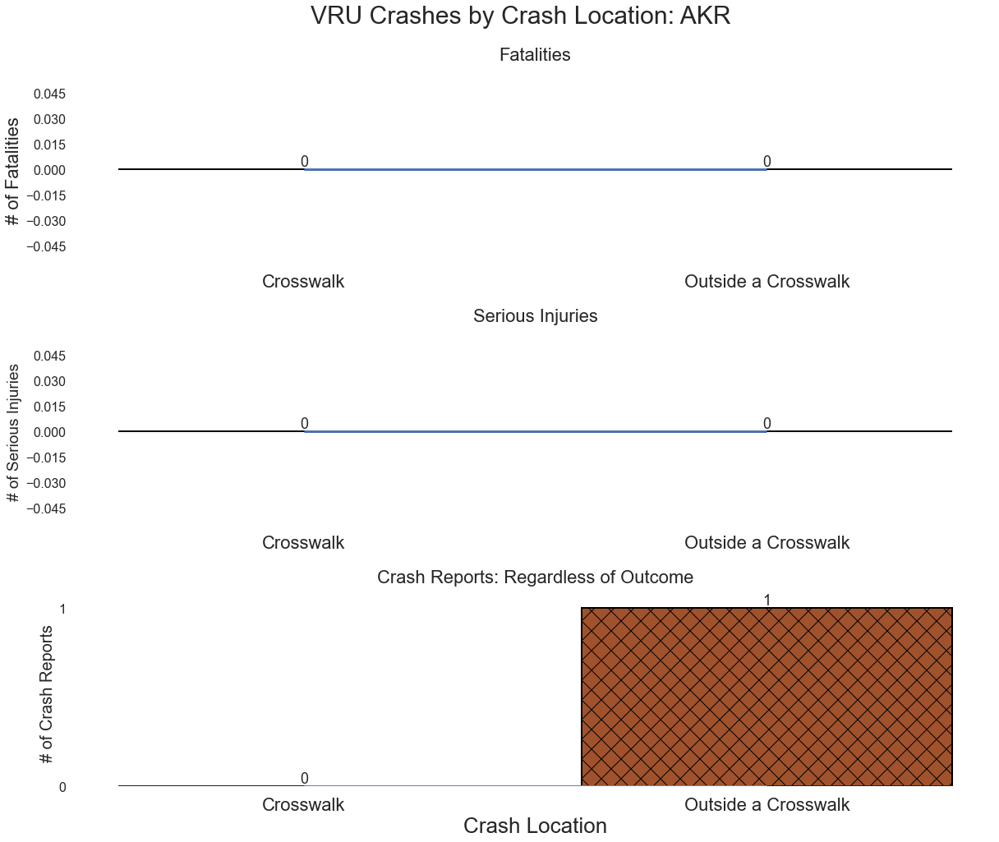

In [91]:
regions = ["NCR","NER","SER","MWR","IMR","PWR","AKR"]
for region in regions:
    create_location_fig_vrus(region)